<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/11_Vulnerability_Software_Supply_Chain_Attacks/QNN_SmartContractVuln_Sridhar2025.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Quantum neural network, QSVM, VQC and quantum random forest for smart-contract vulnerabilities: Sridhar et al. (2025) step by step

**Paper.** Amulyashree Sridhar, Kalyan Nagaraj, Shambhavi Bangalore Ravi, Sindhu Kurup, *Ascertaining Susceptibilities in Smart Contracts: A Quantum Machine Learning Approach*, Entropy 27(9), 933, 2025. DOI [10.3390/e27090933](https://doi.org/10.3390/e27090933).

**What this notebook does.** An Ethereum smart contract is compiled to EVM bytecode. The paper reads the **opcodes** of the bytecode, counts them into a **258-dimensional feature vector**, squeezes it with **PCA**, and feeds the result to four quantum learners: a layered **QNN**, a kernel-based **QSVM**, a **VQC** and a **quantum random forest (QRF)**. The task is "vulnerable or not", and per vulnerability type (gas limit / denial of service, uninitialised storage pointers, access control, reentrancy, overflow). The paper reports that the QNN is clearly the best model (accuracy 82.43 %, F1 81.20 %) and that the three others reach only 62-70 %. This notebook

1. downloads a **public substitute dataset** with real Ethereum contracts, their deployed bytecode and the output of the **Slither** analyser (Hugging Face `mwritescode/slither-audited-smart-contracts`; this is the dataset the paper itself names as its Slither training set),
2. disassembles every bytecode, builds the 258 opcode features (256 opcode-byte frequencies plus two size features), removes duplicate contracts and fits PCA, scaling and every other transform on the training split only,
3. trains the four quantum models of the paper on 10 qubits (QRF: 5-qubit trees drawn from a pool of 20 PCA components) with exact simulators, and a classical Random Forest and RBF-SVM on **exactly the same inputs**,
4. repeats the study per vulnerability type, runs McNemar's test, a multi-seed stability check and a depolarising-noise check,
5. prints the paper's numbers next to ours with one verdict per claim.

**How to run.** Colab, CPU runtime, *Runtime -> Run all*. `FAST_MODE = True` (default in this file) is a class demo that finishes in roughly 10-15 minutes on an idle CPU (about 15 minutes on the shared machine used for validation); the larger budgets for `FAST_MODE = False` are in the configuration cell. No GPU, no quantum hardware and no token are needed (the dataset is public; a Hugging Face token in Colab Secrets as `HF_TOKEN` is used only if present).

**What you get at the end.** Test metrics of all models, confusion matrices, loss curves, per-type tables, the paper-versus-notebook table, and a critical reading of the paper.

**Important substitution (read this first).** The paper tests on the **SolidiFI** benchmark (Solidity sources with injected bugs, compiled to bytecode with `solc`) and trains on three sets: the Slither set, SmartBugs Wild and an expert-audited set that is "available on reasonable request". Here the training and the test data both come from the Slither-audited set (a stratified held-out split), because SolidiFI would need a Solidity compiler download and the expert set is not public. The numbers are therefore **not** the paper's test conditions; see the table below.

## The paper in one page

- **Problem.** Static tools (Mythril, Smartcheck, Slither, Oyente, Securify) rely on hand-written rules and give false positives/negatives; classical ML has memory and cost limits; the authors propose QML.
- **Data.** Training: Slither-audited set (10 000 contracts), SmartBugs Wild (20 000) and an expert-audited set (5 000) = 35 000 code fragments with five vulnerability types (gas limit, uninitialised storage pointers, access control, reentrancy, overflow). Test: **SolidiFI** (9 369 injected bugs; types present: uninitialised pointers, reentrancy, overflow).
- **Preprocessing.** Duplicates removed; contracts compiled to bytecode, validated with Mythril, converted to opcodes: a **258-dimensional** feature set; PCA (also variance threshold and mutual information were tried) to a few components; normalisation; angle encoding into the circuits (Section 3.7).
- **Models (Section 3.7, Tables 4-7).** *QNN*: L = 3 blocks, each with data encoding, trainable R_Y and R_Z rotations and a CNOT ring; read-out `<Z_0>` mapped to a probability `p = (1 + <Z_0>) / 2`; Adam, cross-entropy, batch 128, learning rate 1e-5, dropout 0.1, learning-rate decay 0.97, L2 1e-3. *QSVM*: entangling feature map (RZ rotations + CNOT), quantum kernel `|<0|U(x)^dagger U(x')|0>|^2`, classical SVM with a precomputed kernel, `C = 0.8`. *VQC*: angle encoding + strongly entangling ansatz, 2 layers, 10 qubits, batch 64, Adam, cross-entropy. *QRF*: 220 quantum decision trees, depth 9, 20 qubits, bootstrap + random feature subsets, majority vote.
- **Claims.** Table 8 (SolidiFI test, accuracy / F1): QNN 82.43 / 81.20, QSVM 65.98 / 64.50, VQC 62.41 / 55.50, QRF ("RF" in Table 8) 69.63 / 60.20. Table 9: the same ordering for each vulnerability type (QNN accuracy 81.6-82.8 %). Table 10 / Figure 3: QNN finds more true positives than Mythril, Smartcheck and Slither. McNemar's test (Table 11): QNN differs significantly from the other models for four of five types. Stability over ten seeds, and more than 90 % of the noiseless accuracy kept under depolarising noise `p = 0.01` and `p = 0.05`. Everything on simulators.
- **Internal inconsistencies worth knowing.** The introduction says 81.78 % (then 97.63 % "on a test dataset", 89.96 % on splits), the abstract and Table 8 say 82.43 %; the text says "recall 82.43 %" for the QNN while Table 8 gives recall 81.17 % and accuracy 82.43 %; Table 4 lists dropout, layers and learning-rate decay for a circuit that has none of those; the text says accuracy is stationary "after 2000 epochs" while the grid search stops at 500 epochs; the Table 9 rows of VQC and QRF for access control are identical to those for uninitialised pointers apart from two entries.

## What follows the paper and what had to be chosen

| Item | Paper | This notebook |
|---|---|---|
| Training data | Slither set (10 000) + SmartBugs Wild (20 000) + expert-audited set (5 000) | **Slither-audited set only** (Hugging Face `mwritescode/slither-audited-smart-contracts`, about 135 000 real verified contracts, labels from Slither detectors). SmartBugs Wild labels come from other tools and are not a one-line download; the expert set is not public |
| Test data | SolidiFI (9 369 injected bugs, sources compiled with `solc`) | **Not used.** SolidiFI ships Solidity sources only; compiling needs a solc download, which is outside what this notebook downloads. Test = a stratified **held-out split of the same Slither set** (so easier than the paper's out-of-distribution test) |
| Bytecode | compiled from source, Mythril-validated | the **deployed runtime bytecode** stored in the dataset (no compiler, no Mythril) |
| 258 features | "opcode features", not listed | `# CHOICE:` 256 opcode-byte frequencies (relative to the instruction count, PUSH operands skipped) + log instruction count + log bytecode length = 258 |
| Duplicates | removed | exact bytecode duplicates and contracts with identical feature vectors removed |
| Dimensionality reduction | PCA (also variance threshold, MI tried) | PCA, fitted on the training split only |
| Qubits | VQC 10, QRF 20, QNN/QSVM not stated | QNN, QSVM, VQC 10 qubits; QRF: pool of 20 PCA components, each tree an **exactly simulated 5-qubit** circuit on a random subset (`# CHOICE:`, a 20-qubit tree would not train on CPU) |
| Encoding | "binary basis encoding" (Ventura state preparation) in 3.5, angle encoding in 3.7 | **angle encoding** (R_Y of the PCA components scaled to [0, pi]); the Ventura associative-memory loader loads a whole data set into one superposition and cannot classify single contracts |
| Vulnerability labels | five types: gas limit, uninitialised pointers, access control, reentrancy, overflow | Slither detector groups (`# CHOICE:`): reentrancy = `reentrancy-eth/no-eth`; access control = `suicidal, arbitrary-send, tx-origin, controlled-*, unprotected-upgrade`; uninitialised storage = `uninitialized-storage`; **overflow proxy** = `divide-before-multiply` (Slither has no overflow detector); **gas-limit proxy** = `msg-value-loop`, `delegatecall-loop`. Very rare types are skipped when fewer than `MIN_POS` examples exist |
| Task | vulnerable vs non-vulnerable, and per type | same: positive = flagged for at least one of the five types, negative = Slither flagged nothing; per type: that type vs non-flagged contracts; classes balanced |
| QNN training | Adam, lr 1e-5, batch 128, dropout 0.1, lr decay 0.97, L2 1e-3, up to 500 epochs | Adam, batch 128, L2 1e-3, decay 0.97 per epoch; `# CHOICE:` lr 0.05 and 20-40 epochs (lr 1e-5 does not move a circuit in a few hundred steps); no dropout (the circuit has no hidden layers) |
| QSVM | `C = 0.8`, "Gaussian kernel" and quantum kernel both mentioned | quantum kernel of the entangling feature map (H, RZ, CNOT chain, 2 reps), `C = 0.8`, kernel bandwidth chosen on a validation split of the training data |
| VQC | 2 layers, 10 qubits, batch 64, Adam, cross-entropy | same (PennyLane `StronglyEntanglingLayers`), read-out `<Z_0>`, BCE; `# CHOICE:` lr 0.05 |
| QRF | 220 trees, depth 9, 20 qubits | 5-qubit quantum trees, bootstrap + 5 random features each, majority vote; the number of trees is in the config (220 for the full run); "depth 9" has no meaning for a circuit and is not used |
| Simulation | Qiskit / PennyLane / TensorFlow | **exact batched state-vector simulator in PyTorch**, asserted equal to the PennyLane QNodes that are drawn (PennyLane's own training is ~10 s per step at 10 qubits on CPU); QSVM with Qiskit |
| Noise study | depolarising `p = 0.05, 0.01` | quantum-trajectory depolarising noise after every single-qubit layer and every CNOT ring (`# CHOICE:`), checked against the analytic one-qubit result |
| Statistics | McNemar, ten seeds | McNemar (continuity corrected chi-square and exact binomial) on the same test set; ten seeds in the full run, fewer in `FAST_MODE` |

In [1]:
# Installs, pinned to the versions this notebook was tested with. Colab already ships numpy, pandas, scikit-learn,
# matplotlib, seaborn, scipy, torch and pyarrow. A session restart may be required if an import below fails.
import importlib.util, subprocess, sys
IN_COLAB = "google.colab" in sys.modules
need = []
if IN_COLAB or importlib.util.find_spec("qiskit") is None:
    need += ["qiskit==2.5.2", "qiskit-machine-learning==0.9.1", "pylatexenc"]
if IN_COLAB or importlib.util.find_spec("pennylane") is None:
    need += ["pennylane==0.45.1"]
for pkg in ["huggingface_hub", "pyarrow", "torch", "seaborn"]:
    if importlib.util.find_spec(pkg) is None:
        need.append(pkg)                     # CPU build of torch is enough
if need:
    subprocess.run([sys.executable, "-m", "pip", "-q", "install", *need], check=False)
    print("installed:", need, "(restart the runtime if an import below fails)")
else:
    print("nothing to install")

nothing to install


### Configuration

Every tunable constant is here. `FAST_MODE = True` is the class demo (small samples, few epochs, one seed, the main task plus two vulnerability types, 2 of the 9 data shards). `FAST_MODE = False` is the full run: all 9 shards (so the rare vulnerability types have enough examples), larger samples, more epochs, ten seeds for the stability check and 220 trees. The full run is documented in the table at the end and takes well over an hour on a shared CPU.

In [2]:
# ---------------- configuration: every tunable constant lives here ----------------
SEED = 42
FAST_MODE = True              # True: about 10 minutes; False: full budgets (several times longer)
IBM_TOKEN = ""                  # unused: nothing here runs on quantum hardware
DATA_DIR = "qc143_data"
HF_REPO = "mwritescode/slither-audited-smart-contracts"        # public substitute dataset (CHOICE)
SHARDS = [0, 8] if FAST_MODE else list(range(9))               # raw parquet shards of up to 15 000 contracts
SAMPLE_PER_SHARD = 1500 if FAST_MODE else 3000                 # ordinary contracts kept per shard (rare-type contracts are always kept)

N_QUBITS = 10                   # QNN, QSVM, VQC (paper Table 6: 10 qubits for the VQC)
QRF_POOL = 20                   # PCA components available to the QRF (paper Table 7: qubit count 20)
QRF_TREE_QUBITS = 5             # CHOICE: qubits (= features) per quantum decision tree
QRF_TREES = 8 if FAST_MODE else 220                           # paper: 220 trees
QRF_STEPS = 25                  # Adam steps per tree (CHOICE)

N_PER_CLASS = 250 if FAST_MODE else 800                        # contracts per class and task (balanced)
TEST_SIZE = 0.40 if FAST_MODE else 0.30
MIN_POS = 40                    # a vulnerability type needs at least this many examples to be run
TYPE_TASKS_FAST = ["reentrancy", "access-control"]    # types run in FAST_MODE (the others need the full run)

QNN_BLOCKS, QNN_BATCH, QNN_LR, QNN_L2, QNN_DECAY = 3, 128, 0.05, 1e-3, 0.97     # paper Table 4 (lr is a CHOICE)
VQC_LAYERS, VQC_BATCH, VQC_LR = 2, 64, 0.05                                      # paper Table 6 (lr is a CHOICE)
EPOCHS = 10 if FAST_MODE else 25                               # CHOICE: the paper's 100-500 epochs are out of reach on CPU
QSVM_C, QSVM_REPS = 0.8, 2                                     # paper Table 5
QSVM_BANDWIDTHS = [0.5, 1.0] if FAST_MODE else [0.25, 0.5, 1.0, 2.0]
VAL_FRAC = 0.2                  # part of the training split used only to choose the QSVM bandwidth

SEEDS_BINARY = [42] if FAST_MODE else [42, 43, 44, 45, 46, 47, 48, 49, 50, 51]   # paper: ten seeds
SEEDS_TYPES = [42]
NOISE_LEVELS = [0.01, 0.05]     # paper: depolarising noise p = 0.01 and 0.05
N_NOISE_TEST, N_TRAJ = (60, 8) if FAST_MODE else (200, 16)

In [3]:
import os, json, time, math, random, warnings, collections, itertools
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import torch
import pennylane as qml
import qiskit, sklearn, scipy
import qiskit_machine_learning
from scipy import stats
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
warnings.filterwarnings("ignore")
T_NOTEBOOK = time.time()

# Hugging Face token: the dataset is public, so the token is optional. Resolved only from the environment or Colab Secrets.
HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN is None:
    try:
        from google.colab import userdata          # Colab: Settings > Secrets > HF_TOKEN
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
set_seed(SEED)
rng = np.random.default_rng(SEED)
torch.set_num_threads(max(1, min(4, os.cpu_count() or 1)))
os.makedirs(DATA_DIR, exist_ok=True)
sns.set_theme(style="whitegrid")
print("numpy", np.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__, "| torch", torch.__version__,
      "| pennylane", qml.__version__, "| qiskit", qiskit.__version__, "| qiskit-machine-learning", qiskit_machine_learning.__version__)
print("FAST_MODE =", FAST_MODE, "| HF token available:", HF_TOKEN is not None)

numpy 2.5.4 | pandas 3.0.6 | scikit-learn 1.9.1 | torch 2.14.1+cpu | pennylane 0.45.1 | qiskit 2.5.2 | qiskit-machine-learning 0.9.1
FAST_MODE = True | HF token available: True


## 1. Data: Ethereum contracts labelled by Slither

The paper's first training set is the **Slither audited smart contracts** data of M. Rossini (reference 80): verified Ethereum contracts with their **deployed bytecode** and the result of the **Slither** static analyser. Each raw Parquet shard holds up to 15 000 contracts; we read only the three small columns `contracts`, `bytecode` and `results` (the `source_code` column is most of the 200 MB). If streaming fails, the shard is downloaded to `DATA_DIR`, read, and **deleted again** (shards are larger than 50 MB).

Slither's 38 detector names are the ground-truth labels. The dataset's own `label_mappings.json` groups them into classes; we additionally keep the raw detector names so that the paper's five vulnerability types can be built (see the table above). A contract is **safe** when Slither raised no detector that the dataset does not mark as "ignore".

In [4]:
import pyarrow.parquet as pq
from huggingface_hub import HfFileSystem, hf_hub_download

mapping_path = hf_hub_download(HF_REPO, "data/label_mappings.json", repo_type="dataset", local_dir=DATA_DIR, token=HF_TOKEN)
LABEL_MAP = json.load(open(mapping_path))

# CHOICE: Slither detector groups for the paper's five vulnerability types (Slither has no overflow or gas-limit detector)
TYPES = {
    "reentrancy": {"reentrancy-eth", "reentrancy-no-eth"},
    "access-control": {"suicidal", "arbitrary-send", "tx-origin", "controlled-array-length", "controlled-delegatecall", "unprotected-upgrade"},
    "arithmetic (overflow proxy)": {"divide-before-multiply"},
    "uninitialized-storage": {"uninitialized-storage"},
    "gas-limit (DoS proxy)": {"msg-value-loop", "delegatecall-loop"},
}
RARE = TYPES["uninitialized-storage"] | TYPES["gas-limit (DoS proxy)"]       # always kept when sampling a shard

NAMES = {0x00: "STOP", 0x01: "ADD", 0x02: "MUL", 0x03: "SUB", 0x04: "DIV", 0x05: "SDIV", 0x06: "MOD", 0x07: "SMOD", 0x08: "ADDMOD",
         0x09: "MULMOD", 0x0a: "EXP", 0x0b: "SIGNEXTEND", 0x10: "LT", 0x11: "GT", 0x12: "SLT", 0x13: "SGT", 0x14: "EQ", 0x15: "ISZERO",
         0x16: "AND", 0x17: "OR", 0x18: "XOR", 0x19: "NOT", 0x1a: "BYTE", 0x1b: "SHL", 0x1c: "SHR", 0x1d: "SAR", 0x20: "SHA3",
         0x30: "ADDRESS", 0x31: "BALANCE", 0x32: "ORIGIN", 0x33: "CALLER", 0x34: "CALLVALUE", 0x35: "CALLDATALOAD", 0x36: "CALLDATASIZE",
         0x37: "CALLDATACOPY", 0x38: "CODESIZE", 0x39: "CODECOPY", 0x3a: "GASPRICE", 0x3b: "EXTCODESIZE", 0x3c: "EXTCODECOPY",
         0x3d: "RETURNDATASIZE", 0x3e: "RETURNDATACOPY", 0x3f: "EXTCODEHASH", 0x40: "BLOCKHASH", 0x41: "COINBASE", 0x42: "TIMESTAMP",
         0x43: "NUMBER", 0x44: "DIFFICULTY", 0x45: "GASLIMIT", 0x46: "CHAINID", 0x47: "SELFBALANCE", 0x48: "BASEFEE", 0x50: "POP",
         0x51: "MLOAD", 0x52: "MSTORE", 0x53: "MSTORE8", 0x54: "SLOAD", 0x55: "SSTORE", 0x56: "JUMP", 0x57: "JUMPI", 0x58: "PC",
         0x59: "MSIZE", 0x5a: "GAS", 0x5b: "JUMPDEST", 0xf0: "CREATE", 0xf1: "CALL", 0xf2: "CALLCODE", 0xf3: "RETURN",
         0xf4: "DELEGATECALL", 0xf5: "CREATE2", 0xfa: "STATICCALL", 0xfd: "REVERT", 0xfe: "INVALID", 0xff: "SELFDESTRUCT"}
for k in range(32): NAMES[0x60 + k] = f"PUSH{k+1}"
for k in range(16): NAMES[0x80 + k] = f"DUP{k+1}"; NAMES[0x90 + k] = f"SWAP{k+1}"
for k in range(5): NAMES[0xa0 + k] = f"LOG{k}"
FEATURE_NAMES = [NAMES.get(b, f"OP_0x{b:02x}") for b in range(256)] + ["log_n_instructions", "log_bytecode_bytes"]   # CHOICE: the 258 features

def opcode_features(hexcode):
    # bytecode hex -> 258 features: 256 relative opcode frequencies (PUSH operand bytes are data, not instructions) + 2 size features
    b = np.frombuffer(bytes.fromhex(hexcode[2:] if hexcode.startswith("0x") else hexcode), dtype=np.uint8)
    pushpos = np.flatnonzero((b >= 0x60) & (b <= 0x7F)); is_data = np.zeros(len(b), bool); last = -1
    for p in pushpos:
        if p <= last: continue
        k = int(b[p]) - 0x5F; is_data[p + 1:p + 1 + k] = True; last = p + k
    ins = b[~is_data]
    hist = np.bincount(ins, minlength=256).astype(np.float64)
    return np.r_[hist / max(len(ins), 1), np.log1p(len(ins)), np.log1p(len(b))]

def read_shard(i):
    cols = ["contracts", "bytecode", "results"]
    try:                                                 # stream only three columns, nothing large touches the disk
        with HfFileSystem(token=HF_TOKEN).open(f"datasets/{HF_REPO}/data/raw/contracts{i}.parquet", "rb") as f:
            return pq.ParquetFile(f).read(columns=cols).to_pandas()
    except Exception as e:
        print("streaming failed (", type(e).__name__, "), downloading the whole shard instead")
        p = hf_hub_download(HF_REPO, f"data/raw/contracts{i}.parquet", repo_type="dataset", local_dir=DATA_DIR, token=HF_TOKEN)
        try:
            return pq.read_table(p, columns=cols).to_pandas()
        finally:
            os.remove(p)                                 # files over 50 MB are removed right after reading

def build_shard(i):
    path = os.path.join(DATA_DIR, f"feat_shard{i}_{SAMPLE_PER_SHARD}.pkl")
    if os.path.exists(path):
        return pd.read_pickle(path)
    t0 = time.time(); df = read_shard(i)
    n_raw = len(df)
    df = df[df.bytecode.str.len() > 200].drop_duplicates("bytecode").copy()     # bytecode missing ("0x") or exact duplicate -> dropped
    checks = []
    for r in df.results:
        j = json.loads(r)
        checks.append(tuple(sorted({d["check"] for d in j["results"]["detectors"]})) if j["results"] else ())
    df["checks"] = checks
    rare = df.checks.map(lambda c: bool(RARE & set(c)))
    keep = pd.concat([df[rare], df[~rare].sample(min(SAMPLE_PER_SHARD, int((~rare).sum())), random_state=SEED)])
    F = np.array([opcode_features(h) for h in keep.bytecode])
    out = pd.concat([keep[["contracts", "checks"]].reset_index(drop=True).assign(shard=i),
                     pd.DataFrame(F, columns=FEATURE_NAMES)], axis=1)
    out.to_pickle(path)
    print(f"shard {i}: {n_raw} raw, {len(df)} with bytecode and unique, {len(keep)} kept ({int(rare.sum())} rare-type), {time.time()-t0:.0f} s")
    return out

pool = pd.concat([build_shard(i) for i in SHARDS], ignore_index=True)
n0 = len(pool)
pool = pool.drop_duplicates(subset=FEATURE_NAMES).reset_index(drop=True)       # near-clones (identical opcode statistics) kept once
print(f"pool: {n0} contracts, {len(pool)} after removing identical feature vectors")

def classes_of(checks): return {LABEL_MAP.get(c, "ignore") for c in checks} - {"ignore"}
pool["safe"] = pool.checks.map(lambda c: len(classes_of(c)) == 0)
for t, s in TYPES.items():
    pool[t] = pool.checks.map(lambda c, s=s: bool(set(c) & s))
pool["any_target"] = pool[list(TYPES)].any(axis=1)
def family(r):
    hit = [t for t in TYPES if r[t]]
    if r.safe: return "safe"
    if len(hit) == 1: return hit[0]
    if len(hit) > 1: return "multi-type"
    return "other flags only"
pool["family"] = pool.apply(family, axis=1)
display(pool.family.value_counts().rename("contracts").to_frame())

pool: 2132 contracts, 2109 after removing identical feature vectors


,contracts
family,
safe,732
other flags only,461
multi-type,337
reentrancy,259
access-control,169
arithmetic (overflow proxy),135
gas-limit (DoS proxy),16


## 2. Tasks: which contracts are positive, which are negative

For the main task (the paper's Table 8) **positive = flagged for at least one of the five types, negative = Slither raised nothing** (contracts that only carry other flags, such as `unused-return`, are in neither class and are left out). For the per-type tasks (Table 9) the positives are the contracts flagged for that type and the negatives are the same non-flagged ones. Classes are balanced; a type with fewer than `MIN_POS` positives is not run and its verdicts read "cannot be checked".

In [5]:
safe_pool = pool[pool.safe]
TASKS = {"vulnerable vs safe": pool[pool.any_target]}
for t in TYPES:
    TASKS[t] = pool[pool[t]]
avail = pd.DataFrame({"positives available": {k: len(v) for k, v in TASKS.items()}, "safe available": len(safe_pool)})
avail["run"] = [("yes" if (k == "vulnerable vs safe" or (len(v) >= MIN_POS and (not FAST_MODE or k in TYPE_TASKS_FAST))) else "no") for k, v in TASKS.items()]
display(avail)
RUN_TASKS = [k for k in TASKS if avail.loc[k, "run"] == "yes"]
print("tasks that will run:", RUN_TASKS)

def make_task(task, seed):
    # balanced sample, stratified split, then PCA / scaling fitted on the training split ONLY
    pos, neg = TASKS[task], safe_pool
    n = min(N_PER_CLASS, len(pos), len(neg))
    d = pd.concat([pos.sample(n, random_state=seed), neg.sample(n, random_state=seed)]).reset_index(drop=True)
    y = np.r_[np.ones(n), np.zeros(n)].astype(int)
    idx_tr, idx_te = train_test_split(np.arange(len(d)), test_size=TEST_SIZE, stratify=y, random_state=seed)
    X = d[FEATURE_NAMES].to_numpy()
    sc = StandardScaler().fit(X[idx_tr])
    pca = PCA(QRF_POOL, random_state=seed).fit(sc.transform(X[idx_tr]))                  # 20 components; QNN/QSVM/VQC use the first 10
    Z = pca.transform(sc.transform(X))
    mm = MinMaxScaler((0, np.pi)).fit(Z[idx_tr])                                          # angles in [0, pi]
    A = np.clip(mm.transform(Z), 0, np.pi)                                                # test angles clipped to [0, pi]
    return dict(task=task, seed=seed, X=X, Z=Z, A=A, y=y, tr=idx_tr, te=idx_te, fam=d.family.to_numpy(), n=n,
                Xtr=X[idx_tr], Xte=X[idx_te], Atr=A[idx_tr], Ate=A[idx_te], ytr=y[idx_tr], yte=y[idx_te], pca=pca)
D0 = make_task("vulnerable vs safe", SEED)
print("main task: train", D0["Xtr"].shape, "test", D0["Xte"].shape, "| classes train", np.bincount(D0["ytr"]), "test", np.bincount(D0["yte"]))
print("PCA variance explained by the first 10 / 20 components:", D0["pca"].explained_variance_ratio_[:10].sum().round(3), D0["pca"].explained_variance_ratio_.sum().round(3))

,positives available,safe available,run
vulnerable vs safe,916,732,yes
reentrancy,567,732,yes
access-control,383,732,yes
arithmetic (overflow proxy),338,732,no
uninitialized-storage,10,732,no
gas-limit (DoS proxy),32,732,no


tasks that will run: ['vulnerable vs safe', 'reentrancy', 'access-control']


main task: train (300, 258) test (200, 258) | classes train [150 150] test [100 100]
PCA variance explained by the first 10 / 20 components: 0.359 0.524


## Dataset Exploration and Visualisation

All plots below show **real contracts** and their **real Slither labels**; nothing is simulated. First the size, the 258 feature names and the original labels (the raw Slither detector names and their class mapping), then the class distribution, then two 2-D scatter plots of the training contracts of the main task coloured by vulnerability family: first the **raw PCA coordinates** (fitted on the training split), then the same two coordinates **scaled to [0, pi]**, which are the rotation angles the circuits receive.

In [6]:
print("pool shape (contracts x [meta + 258 features + labels]):", pool.shape)
print("main task feature matrix:", D0["X"].shape, "| train", D0["Xtr"].shape, "| test", D0["Xte"].shape)
print("feature names (258): first 12 :", FEATURE_NAMES[:12])
print("                     last 6   :", FEATURE_NAMES[-6:])
raw = collections.Counter(c for cs in pool.checks for c in cs)
print("\noriginal labels: raw Slither detector names and counts (contracts in the pool)")
print(pd.Series(raw).sort_values(ascending=False).to_string())
print("\nclass mapping used by the dataset (detector -> class) for the five paper types' detectors:")
for t, s in TYPES.items():
    print(f"  {t:28s}", {c: LABEL_MAP.get(c) for c in sorted(s)})
print("\nground-truth family counts in the pool:")
print(pool.family.value_counts().to_string())

pool shape (contracts x [meta + 258 features + labels]): (2109, 269)
main task feature matrix: (500, 258) | train (300, 258) | test (200, 258)
feature names (258): first 12 : ['STOP', 'ADD', 'MUL', 'SUB', 'DIV', 'SDIV', 'MOD', 'SMOD', 'ADDMOD', 'MULMOD', 'EXP', 'SIGNEXTEND']
                     last 6   : ['OP_0xfc', 'REVERT', 'INVALID', 'SELFDESTRUCT', 'log_n_instructions', 'log_bytecode_bytes']

original labels: raw Slither detector names and counts (contracts in the pool)
unused-return              567
divide-before-multiply     338
reentrancy-no-eth          335
reentrancy-eth             296
uninitialized-local        253
arbitrary-send             251
unchecked-transfer         243
incorrect-equality         235
locked-ether               144
erc20-interface            142
uninitialized-state         92
controlled-array-length     86
tautology                   78
constant-function-asm       67
weak-prng                   56
tx-origin                   47
shadowing-state        

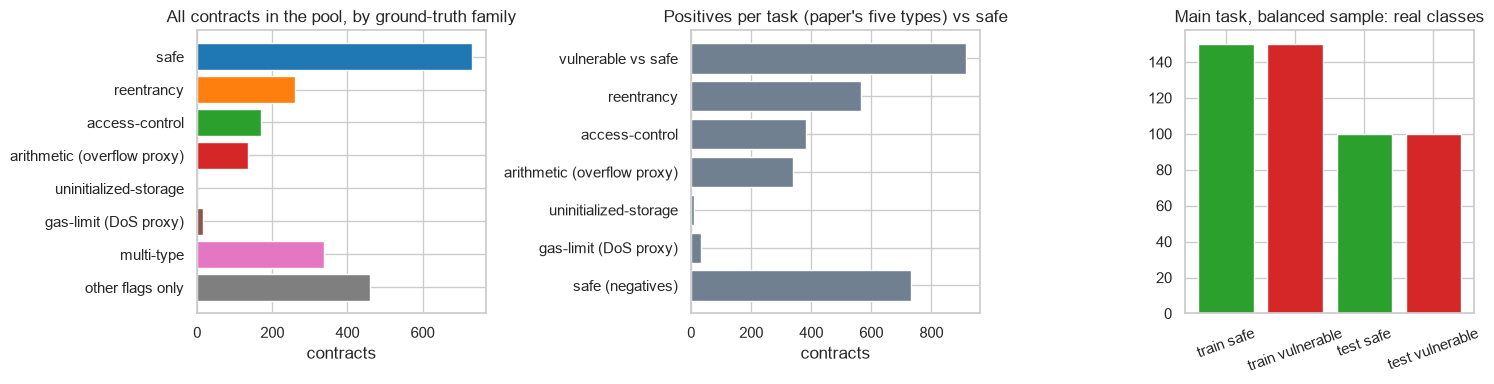

pool: 2109 real contracts; the main task uses 250 per class


In [7]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
order = ["safe", "reentrancy", "access-control", "arithmetic (overflow proxy)", "uninitialized-storage", "gas-limit (DoS proxy)", "multi-type", "other flags only"]
vc = pool.family.value_counts().reindex(order).fillna(0)
ax[0].barh(vc.index[::-1], vc.values[::-1], color=sns.color_palette("tab10", len(vc))[::-1]); ax[0].set_title("All contracts in the pool, by ground-truth family"); ax[0].set_xlabel("contracts")
tt = pd.Series({k: len(v) for k, v in TASKS.items()}); tt["safe (negatives)"] = len(safe_pool)
ax[1].barh(tt.index[::-1], tt.values[::-1], color="slategray"); ax[1].set_title("Positives per task (paper's five types) vs safe"); ax[1].set_xlabel("contracts")
ytrue = pd.Series({"train safe": int((D0["ytr"] == 0).sum()), "train vulnerable": int((D0["ytr"] == 1).sum()),
                   "test safe": int((D0["yte"] == 0).sum()), "test vulnerable": int((D0["yte"] == 1).sum())})
ax[2].bar(ytrue.index, ytrue.values, color=["tab:green", "tab:red", "tab:green", "tab:red"]); ax[2].set_title("Main task, balanced sample: real classes"); ax[2].tick_params(axis="x", rotation=20)
plt.tight_layout(); plt.show()
print(f"pool: {len(pool)} real contracts; the main task uses {D0['n']} per class")

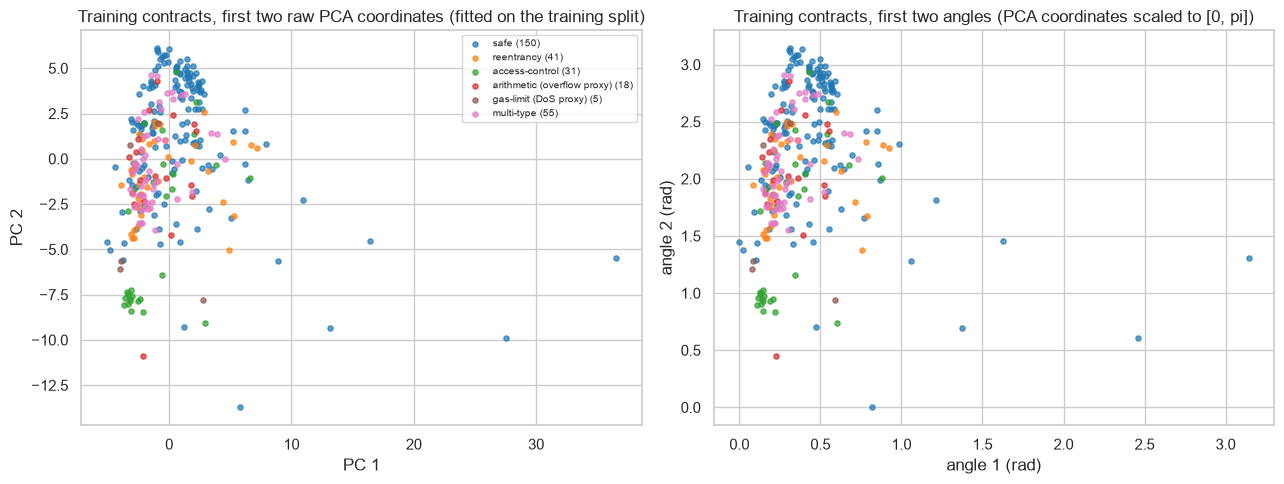

opcodes more frequent in vulnerable contracts: ['PUSH2', 'PUSH1', 'JUMPDEST', 'SHL', 'JUMP', 'JUMPI']
opcodes more frequent in safe contracts      : ['SWAP1', 'PUSH20', 'AND', 'DUP1', 'DUP2', 'ADD']


In [8]:
# 2-D scatter of real training contracts, coloured by ground-truth family (multi-class attack labels kept)
FAM_COLORS = dict(zip(order, sns.color_palette("tab10", len(order))))
ftr = D0["fam"][D0["tr"]]
Ztr2 = D0["Z"][D0["tr"]][:, :2]; Atr2 = D0["A"][D0["tr"]][:, :2]
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for f in order:
    m = ftr == f
    if m.any():
        ax[0].scatter(Ztr2[m, 0], Ztr2[m, 1], s=14, alpha=0.7, color=FAM_COLORS[f], label=f"{f} ({m.sum()})")
        ax[1].scatter(Atr2[m, 0], Atr2[m, 1], s=14, alpha=0.7, color=FAM_COLORS[f])
ax[0].set_title("Training contracts, first two raw PCA coordinates (fitted on the training split)"); ax[0].set_xlabel("PC 1"); ax[0].set_ylabel("PC 2")
ax[1].set_title("Training contracts, first two angles (PCA coordinates scaled to [0, pi])"); ax[1].set_xlabel("angle 1 (rad)"); ax[1].set_ylabel("angle 2 (rad)")
ax[0].legend(fontsize=7, loc="best"); plt.tight_layout(); plt.show()
# which opcodes separate vulnerable from safe contracts? (mean relative frequency, top differences)
dfm = pd.DataFrame(D0["Xtr"], columns=FEATURE_NAMES)
diff = (dfm[D0["ytr"] == 1].mean() - dfm[D0["ytr"] == 0].mean()).iloc[:256]
print("opcodes more frequent in vulnerable contracts:", list(diff.sort_values().index[-6:][::-1]))
print("opcodes more frequent in safe contracts      :", list(diff.sort_values().index[:6]))

## 3. Classical baselines on exactly the same inputs

The paper compares only QML models with each other (and with the Mythril/Smartcheck/Slither tools), so it never shows whether a classical model reaches the same accuracy. We train a **Random Forest** and an **RBF-SVM** on the very same 10 angle features the quantum models see, plus a Random Forest on **all 258 opcode features** (to see how much the 10-dimensional PCA bottleneck costs).

In [9]:
def metrics(y, p):
    return dict(acc=accuracy_score(y, p) * 100, prec=precision_score(y, p, zero_division=0) * 100,
                rec=recall_score(y, p, zero_division=0) * 100, f1=f1_score(y, p, zero_division=0) * 100)

def run_classical(D, seed):
    out = {}; A10tr, A10te = D["Atr"][:, :N_QUBITS], D["Ate"][:, :N_QUBITS]
    for name, mk, (a, b) in [("RF (10 inputs)", lambda: RandomForestClassifier(300, random_state=seed, n_jobs=2), (A10tr, A10te)),
                             ("SVC rbf (10 inputs)", lambda: SVC(kernel="rbf", C=QSVM_C, random_state=seed), (A10tr, A10te)),
                             ("RF (all 258 features)", lambda: RandomForestClassifier(300, random_state=seed, n_jobs=2), (D["Xtr"], D["Xte"]))]:
        t0 = time.time(); m = mk().fit(a, D["ytr"]); p = m.predict(b)
        out[name] = dict(**metrics(D["yte"], p), train_s=time.time() - t0, pred=p)
    return out
cl = run_classical(D0, SEED)
print(pd.DataFrame({k: {m: round(v[m], 1) for m in ["acc", "prec", "rec", "f1"]} for k, v in cl.items()}).T)

                        acc  prec   rec    f1
RF (10 inputs)         82.0  83.3  80.0  81.6
SVC rbf (10 inputs)    82.5  82.2  83.0  82.6
RF (all 258 features)  82.5  85.7  78.0  81.7


## Quantum Circuit Architecture

This section draws the circuits that are **actually executed** and proves that the fast simulator used for training computes the same numbers as the drawn circuit.

- **QNN** (paper Section 3.7 i, Eq. 22; Table 4: 3 blocks): `H` on every qubit, then 3 blocks of [`R_Y(x_i)` data encoding, `R_Y(theta)` `R_Z(phi)` on every qubit, a **ring of CNOTs**]; read-out `<Z_0>`. The data are **re-uploaded** in every block. 10 qubits, `3 x 10 x 2 = 60` trainable parameters.
- **VQC** (Section 3.7 iii, Table 6: 2 layers, 10 qubits): `H`, one `R_Y(x_i)` angle encoding, then 2 `StronglyEntanglingLayers` (a general rotation on every qubit and CNOTs with increasing range). 60 trainable parameters.
- **QRF tree** (Section 3.7 iv): 5 qubits, 2 blocks of the QNN type on a random subset of 5 PCA components, decision qubit `Z_0`; 20 trainable parameters per tree, `QRF_TREES` trees.
- **QSVM feature map** (Section 3.7 ii, Eq. 23): Qiskit circuit with `H`, `R_Z(bandwidth * x_i)`, a chain of CNOTs, repeated twice; no trainable parameters, the kernel is `|<phi(x)|phi(x')>|^2`.

**Assumptions where the paper is silent** (`# CHOICE:`): the paper gives no gate-level circuit (its Figure 2 is an input / encoding / learning / output block diagram with Hadamard and CNOT gates), so the Hadamard layer, the CNOT ring/chain, the rotation axes, the read-out qubit, the number of repetitions of the QSVM map and the use of `StronglyEntanglingLayers` for the VQC are our reading of the text. Training uses an exact batched state-vector simulator written in PyTorch (below) because PennyLane's own back-propagation needs about 10 s per step at 10 qubits on a CPU; every model's circuit is also built as a PennyLane QNode / Qiskit circuit, drawn, and **asserted equal** to the simulator.

In [10]:
CD = torch.complex128
def ry_mat(a):                       # a [B] -> [B,2,2]
    c, s = torch.cos(a / 2), torch.sin(a / 2)
    return torch.stack([torch.stack([c, -s], -1), torch.stack([s, c], -1)], -2).to(CD)
def rz_mat(a):
    e = torch.exp(-0.5j * a.to(CD)); z = torch.zeros_like(e)
    return torch.stack([torch.stack([e, z], -1), torch.stack([z, e.conj()], -1)], -2)
def rot_mat(phi, theta, omega):      # PennyLane Rot(phi, theta, omega) = RZ(omega) RY(theta) RZ(phi)
    c, s = torch.cos(theta / 2).to(CD), torch.sin(theta / 2).to(CD)
    ep = lambda a: torch.exp(1j * a.to(CD))
    return torch.stack([torch.stack([ep(-(phi + omega) / 2) * c, -ep((phi - omega) / 2) * s], -1),
                        torch.stack([ep(-(phi - omega) / 2) * s,  ep((phi + omega) / 2) * c], -1)], -2)
HAD = torch.tensor([[1, 1], [1, -1]], dtype=CD) / math.sqrt(2)
PAULI = torch.stack([torch.eye(2, dtype=CD), torch.tensor([[0, 1], [1, 0]], dtype=CD),
                     torch.tensor([[0, -1j], [1j, 0]], dtype=CD), torch.tensor([[1, 0], [0, -1]], dtype=CD)])

def kron_all(mats):                  # list of [B,2,2] -> [B, 2^k, 2^k]
    K = mats[0]
    for M in mats[1:]:
        B, d = K.shape[0], K.shape[1]
        K = (K[:, :, None, :, None] * M[:, None, :, None, :]).reshape(B, 2 * d, 2 * d)
    return K

class Sim:
    # Exact batched state-vector simulator. The state of n qubits is a matrix [B, 2^nl, 2^nr]; qubit 0 is the most significant bit
    # (the PennyLane convention). A layer with one single-qubit gate per qubit is K_left @ S @ K_right^T.
    def __init__(self, n):
        self.n, self.nl = n, n // 2; self.nr = n - self.nl
    def layer(self, S, mats):
        KL, KR = kron_all(mats[:self.nl]), kron_all(mats[self.nl:])
        return KL @ S @ KR.transpose(1, 2)
    def product(self, mats):         # prod_i M_i |0>
        KL, KR = kron_all(mats[:self.nl]), kron_all(mats[self.nl:])
        return KL[:, :, :1] @ KR[:, :, :1].transpose(1, 2)
    def perm(self, S, p):            # a fixed pattern of CNOTs is a permutation of basis states
        B = S.shape[0]; return S.reshape(B, -1)[:, p].reshape(B, 2 ** self.nl, 2 ** self.nr)
    def z0(self, S):                 # <Z_0>
        pr = S.abs() ** 2; h = 2 ** (self.nl - 1)
        return pr[:, :h].sum((1, 2)) - pr[:, h:].sum((1, 2))

def cnot_perm(pairs, n):             # gather index for a sequence of CNOT(control, target)
    idx = np.arange(2 ** n); cur = idx.copy()
    for c, t in pairs:
        cb = (cur >> (n - 1 - c)) & 1
        cur = np.where(cb == 1, cur ^ (1 << (n - 1 - t)), cur)
    inv = np.empty_like(cur); inv[cur] = idx
    return torch.tensor(inv, dtype=torch.long)
def ring(n): return cnot_perm([(i, (i + 1) % n) for i in range(n)], n)
def sel_perms(n, layers): return [cnot_perm([(i, (i + (l % (n - 1)) + 1) % n) for i in range(n)], n) for l in range(layers)]   # StronglyEntanglingLayers default ranges

def noise_layer(sim, S, p, gen):     # depolarising event per qubit and trajectory: with prob p a random Pauli X, Y or Z
    B = S.shape[0]; mats = []
    for _ in range(sim.n):
        hit = torch.rand(B, generator=gen) < p
        which = torch.where(hit, torch.randint(1, 4, (B,), generator=gen), torch.zeros(B, dtype=torch.long))
        mats.append(PAULI[which])
    return sim.layer(S, mats)

def qnn_forward(sim, x, w, perm, noise=None):          # x [B,n] angles, w [L,n,2]; returns <Z_0> of every sample
    B, L, n = x.shape[0], w.shape[0], sim.n; S = None
    for l in range(L):
        mats = [rz_mat(w[l, i, 1].expand(B)) @ ry_mat(x[:, i] + w[l, i, 0]) for i in range(n)]   # RZ(phi) RY(theta) RY(x) = RZ(phi) RY(x + theta)
        S = sim.product([m @ HAD for m in mats]) if l == 0 else sim.layer(S, mats)
        if noise: S = noise(S)
        S = sim.perm(S, perm)
        if noise: S = noise(S)
    return sim.z0(S)

def vqc_forward(sim, x, w, perms):                     # w [L,n,3]
    B, L, n = x.shape[0], w.shape[0], sim.n
    S = sim.product([ry_mat(x[:, i]) @ HAD for i in range(n)])
    for l in range(L):
        S = sim.layer(S, [rot_mat(w[l, i, 0], w[l, i, 1], w[l, i, 2]).reshape(1, 2, 2).expand(B, 2, 2) for i in range(n)])
        S = sim.perm(S, perms[l])
    return sim.z0(S)
print("simulator ready")

simulator ready


In [11]:
# The PennyLane QNodes that are drawn (the real circuits) and the assertions that the fast simulator equals them.
n = N_QUBITS
dev10 = qml.device("default.qubit", wires=n)
@qml.qnode(dev10, interface="torch")
def qnn_qnode(x, w):
    for i in range(n): qml.Hadamard(i)
    for l in range(QNN_BLOCKS):
        qml.AngleEmbedding(x, wires=range(n), rotation="Y")                      # data encoding (re-uploaded every block)
        for i in range(n):
            qml.RY(w[l, i, 0], wires=i); qml.RZ(w[l, i, 1], wires=i)             # trainable rotations
        for i in range(n): qml.CNOT(wires=[i, (i + 1) % n])                      # CNOT ring
    return qml.expval(qml.PauliZ(0))

@qml.qnode(dev10, interface="torch")
def vqc_qnode(x, w):
    for i in range(n): qml.Hadamard(i)
    qml.AngleEmbedding(x, wires=range(n), rotation="Y")
    qml.StronglyEntanglingLayers(w, wires=range(n))
    return qml.expval(qml.PauliZ(0))

def tree_qnode_factory(nq, blocks=2):
    d = qml.device("default.qubit", wires=nq)
    @qml.qnode(d, interface="torch")
    def f(x, w):
        for i in range(nq): qml.Hadamard(i)
        for l in range(blocks):
            qml.AngleEmbedding(x, wires=range(nq), rotation="Y")
            for i in range(nq):
                qml.RY(w[l, i, 0], wires=i); qml.RZ(w[l, i, 1], wires=i)
            for i in range(nq): qml.CNOT(wires=[i, (i + 1) % nq])
        return qml.expval(qml.PauliZ(0))
    return f
tree_qnode = tree_qnode_factory(QRF_TREE_QUBITS)

g = torch.Generator().manual_seed(SEED)
xs = torch.rand(4, n, generator=g, dtype=torch.float64) * math.pi
wq = torch.randn(QNN_BLOCKS, n, 2, generator=g, dtype=torch.float64)
wv = torch.randn(VQC_LAYERS, n, 3, generator=g, dtype=torch.float64)
sim10, sim5 = Sim(n), Sim(QRF_TREE_QUBITS)
ring10, ring5, perms_v = ring(n), ring(QRF_TREE_QUBITS), sel_perms(n, VQC_LAYERS)
a, b = qnn_qnode(xs, wq), qnn_forward(sim10, xs, wq, ring10)
assert torch.allclose(a, b, atol=1e-10), "QNN simulator differs from the PennyLane QNode"
print("QNN  : fast simulator == PennyLane QNode, max |diff| =", float((a - b).abs().max()))
a, b = vqc_qnode(xs, wv), vqc_forward(sim10, xs, wv, perms_v)
assert torch.allclose(a, b, atol=1e-10), "VQC simulator differs from the PennyLane QNode"
print("VQC  : fast simulator == PennyLane QNode, max |diff| =", float((a - b).abs().max()))
x5, w5 = xs[:, :QRF_TREE_QUBITS], torch.randn(2, QRF_TREE_QUBITS, 2, generator=g, dtype=torch.float64)
a, b = tree_qnode(x5, w5), qnn_forward(sim5, x5, w5, ring5)
assert torch.allclose(a, b, atol=1e-10), "tree simulator differs from the PennyLane QNode"
print("tree : fast simulator == PennyLane QNode, max |diff| =", float((a - b).abs().max()))
# the noise model: one depolarising event after one R_Y on qubit 0 must give <Z_0> = (1 - 4p/3) cos(x)  (analytic)
s2 = Sim(2); xa = torch.full((20000,), 0.9, dtype=torch.float64); gen = torch.Generator().manual_seed(1); p_chk = 0.15
S = s2.product([ry_mat(xa), ry_mat(torch.zeros(20000, dtype=torch.float64))]); S = noise_layer(s2, S, p_chk, gen)
print("noise: trajectory estimate", round(float(s2.z0(S).mean()), 3), "| analytic (1-4p/3)cos(x) =", round((1 - 4 * p_chk / 3) * math.cos(0.9), 3))
assert abs(float(s2.z0(S).mean()) - (1 - 4 * p_chk / 3) * math.cos(0.9)) < 0.02

QNN  : fast simulator == PennyLane QNode, max |diff| = 5.551115123125783e-17


VQC  : fast simulator == PennyLane QNode, max |diff| = 5.551115123125783e-17
tree : fast simulator == PennyLane QNode, max |diff| = 1.6653345369377348e-16


noise: trajectory estimate 0.496 | analytic (1-4p/3)cos(x) = 0.497


Matplotlib is building the font cache; this may take a moment.


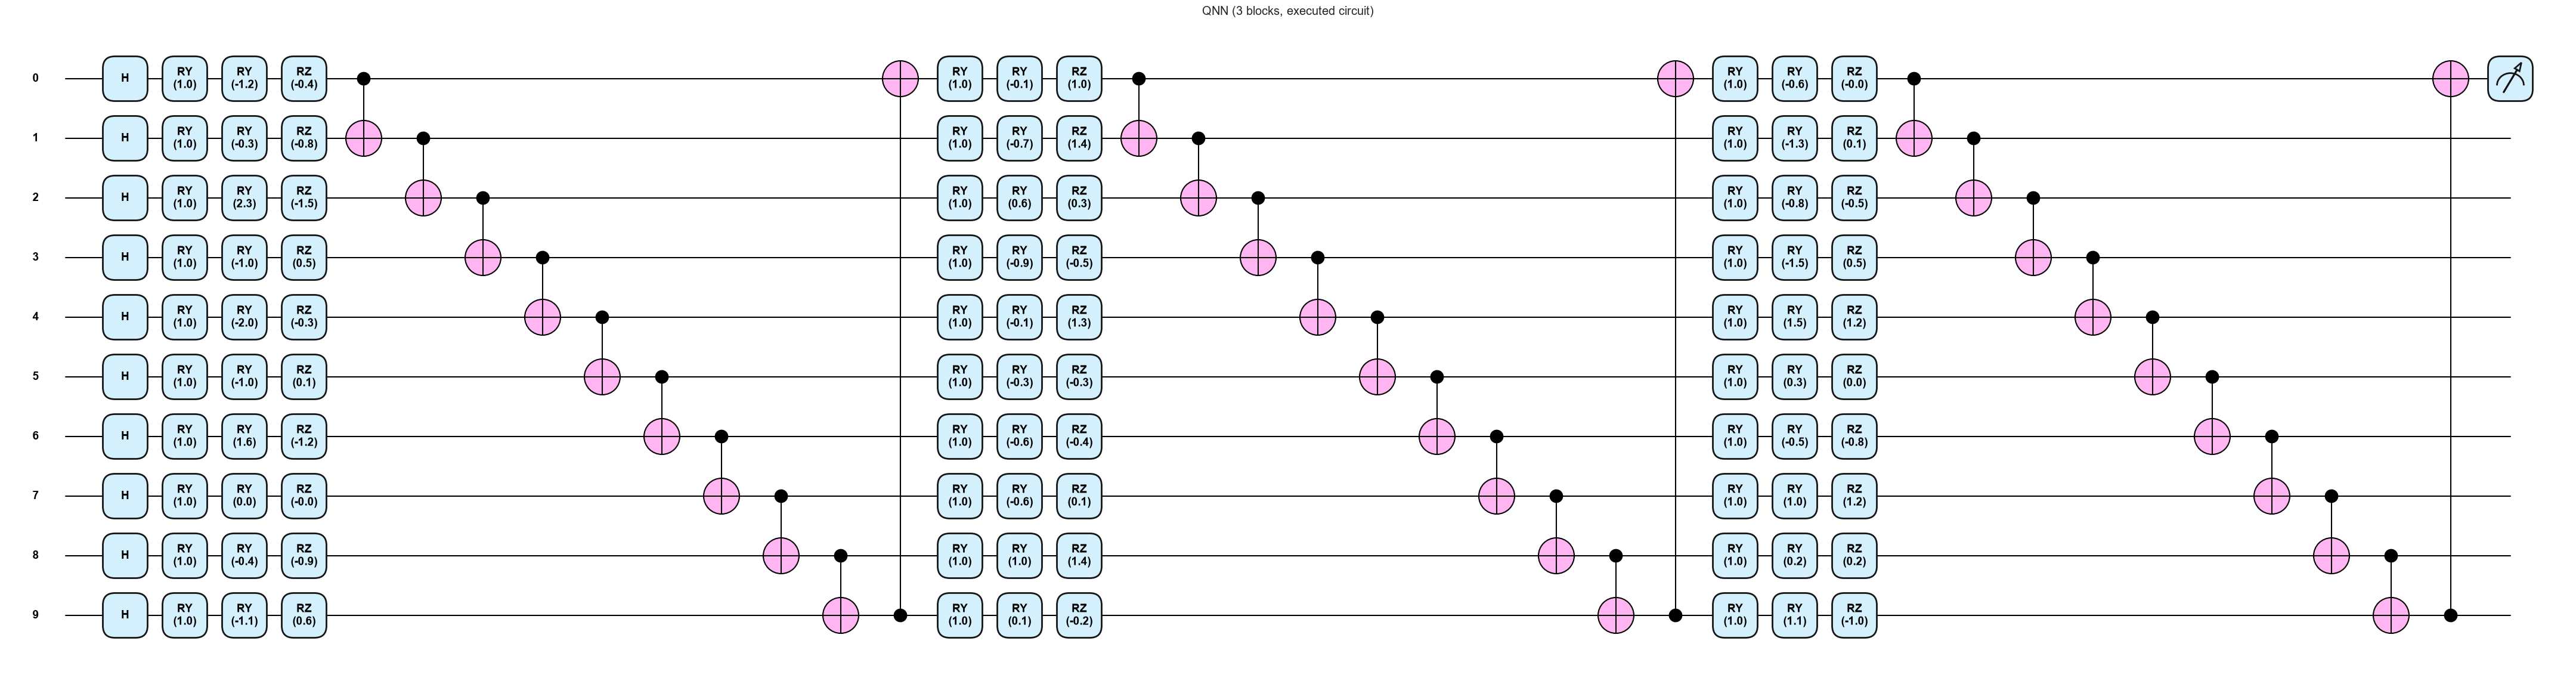

QNN : qubits 10, depth 40, gates 130, trainable parameters 60


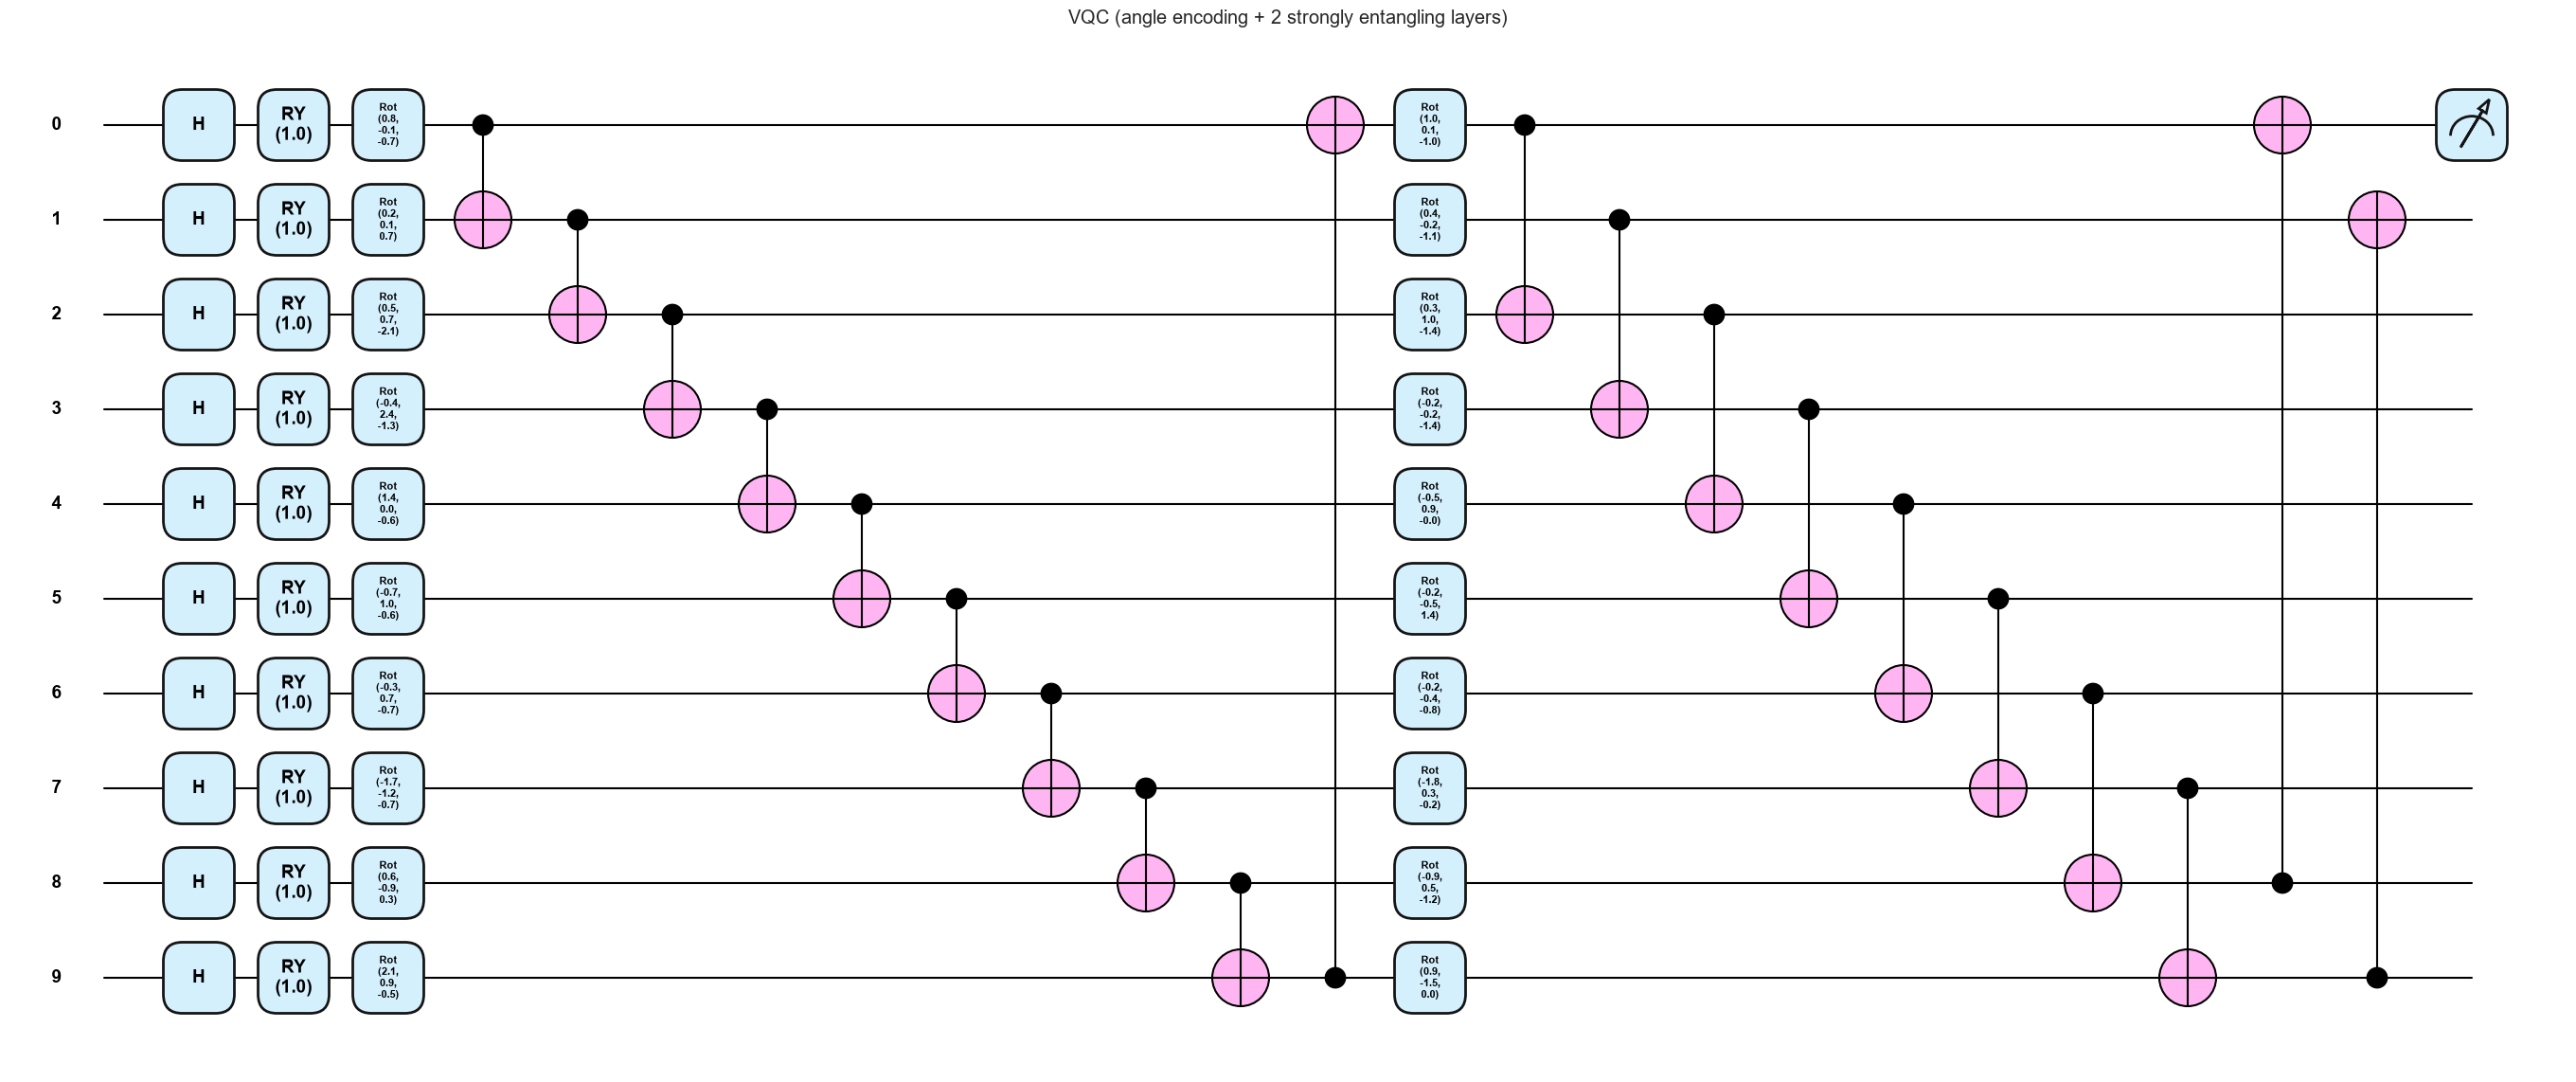

VQC : qubits 10, depth 19, gates 60, trainable parameters 60


Matplotlib is building the font cache; this may take a moment.


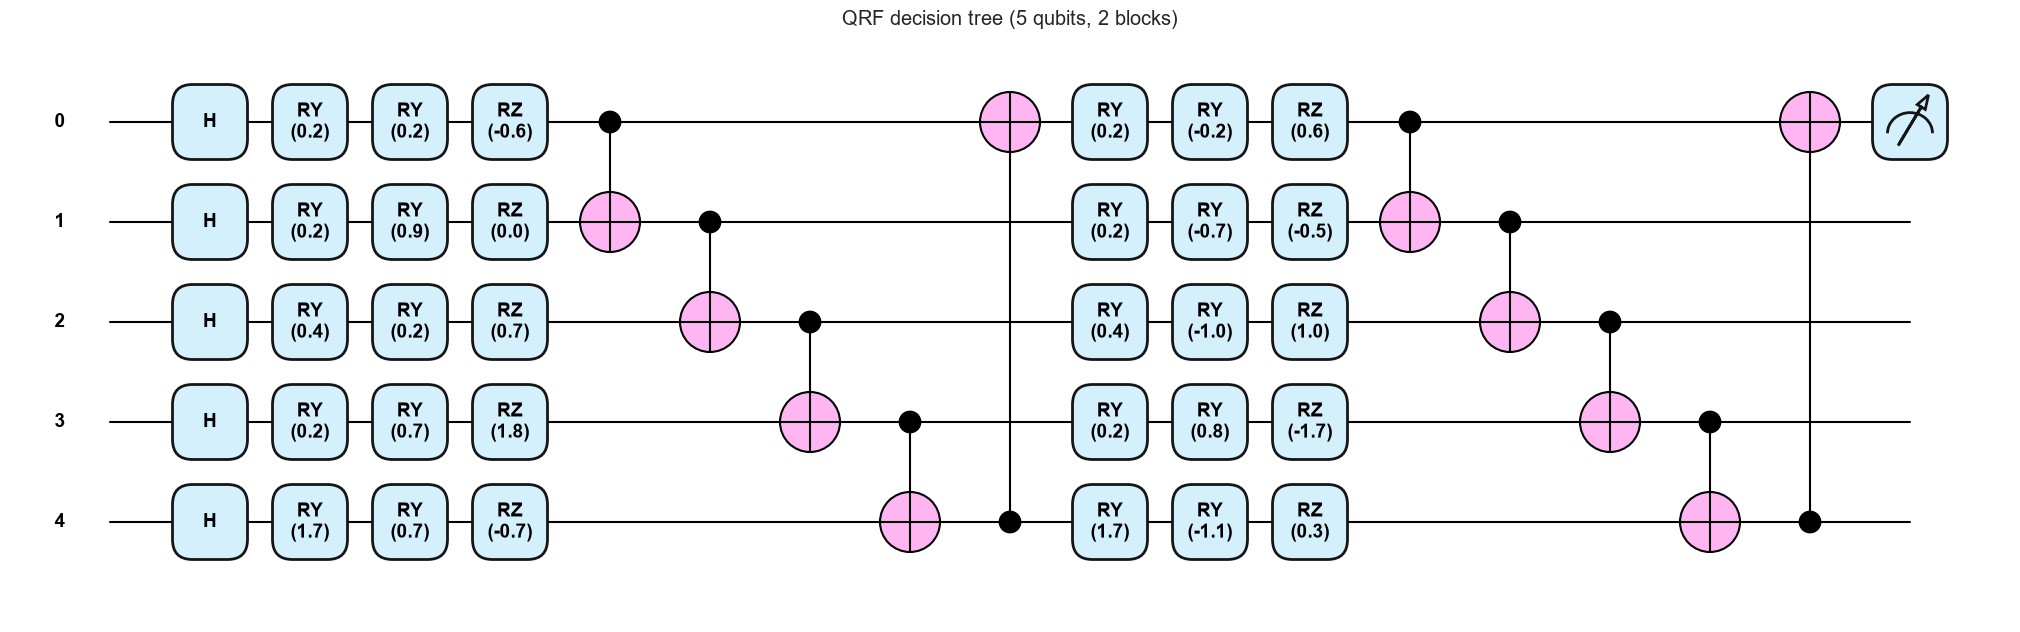

QRF tree : qubits 5, depth 17, gates 45, trainable parameters 20 per tree, 8 trees


In [12]:
x1 = torch.full((n,), 1.0, dtype=torch.float64)
def specs_of(qnode, *args):
    tape = qml.workflow.construct_batch(qnode, level="device")(*args)[0][0]
    return tape.wires.__len__(), tape.graph.get_depth(), len(tape.operations)
nq_a, dep_a, ops_a = specs_of(qnn_qnode, x1, wq)
fig, _ = qml.draw_mpl(qnn_qnode, decimals=1, style="pennylane", level="device")(x1, wq); fig.suptitle("QNN (3 blocks, executed circuit)", y=1.02); plt.show()
print(f"QNN : qubits {nq_a}, depth {dep_a}, gates {ops_a}, trainable parameters {wq.numel()}")
nq_b, dep_b, ops_b = specs_of(vqc_qnode, x1, wv)
fig, _ = qml.draw_mpl(vqc_qnode, decimals=1, style="pennylane", level="device")(x1, wv); fig.suptitle("VQC (angle encoding + 2 strongly entangling layers)", y=1.02); plt.show()
print(f"VQC : qubits {nq_b}, depth {dep_b}, gates {ops_b}, trainable parameters {wv.numel()}")
nq_c, dep_c, ops_c = specs_of(tree_qnode, x5[0], w5)
fig, _ = qml.draw_mpl(tree_qnode, decimals=1, style="pennylane", level="device")(x5[0], w5); fig.suptitle("QRF decision tree (5 qubits, 2 blocks)", y=1.02); plt.show()
print(f"QRF tree : qubits {nq_c}, depth {dep_c}, gates {ops_c}, trainable parameters {w5.numel()} per tree, {QRF_TREES} trees")

In [13]:
from qiskit import QuantumCircuit, transpile
from qiskit.circuit import ParameterVector
from qiskit.quantum_info import Statevector
from qiskit_machine_learning.kernels import FidelityStatevectorKernel

def entangling_feature_map(nq, reps=QSVM_REPS):
    # CHOICE: paper Eq. 23: "each qubit undergoes R_Z(alpha_i x_i) followed by CNOT entanglement"; H first so that R_Z acts non-trivially
    x = ParameterVector("x", nq); qc = QuantumCircuit(nq)
    for _ in range(reps):
        qc.h(range(nq))
        for i in range(nq): qc.rz(x[i], i)
        for i in range(nq - 1): qc.cx(i, i + 1)
    return qc
FMAP = entangling_feature_map(N_QUBITS)
fig = FMAP.draw("mpl", fold=-1); fig.suptitle("QSVM feature map U(x) (executed circuit; x scaled by the bandwidth)"); plt.show()
print(f"QSVM feature map : qubits {FMAP.num_qubits}, depth {FMAP.decompose().depth()}, gates {sum(FMAP.count_ops().values())}, data parameters {FMAP.num_parameters}, trainable parameters 0 (the SVM has its dual coefficients)")

def statevectors(A, bw):
    return np.array([Statevector(FMAP.assign_parameters(dict(zip(FMAP.parameters, bw * a)))).data for a in A])
def quantum_kernel(SA, SB):
    return np.abs(SA.conj() @ SB.T) ** 2                # |<phi(a)|phi(b)>|^2, Eq. 23

# equivalence: the hand-computed kernel equals Qiskit's FidelityStatevectorKernel on the same circuit
chk = D0["Atr"][:12, :N_QUBITS]
K_hand = quantum_kernel(statevectors(chk, 1.0), statevectors(chk, 1.0))
K_qiskit = FidelityStatevectorKernel(feature_map=FMAP).evaluate(chk, chk)
assert np.allclose(K_hand, K_qiskit, atol=1e-8), "hand kernel differs from FidelityStatevectorKernel"
print("QSVM kernel: hand-computed |<phi(a)|phi(b)>|^2 == FidelityStatevectorKernel, max |diff| =", float(np.abs(K_hand - K_qiskit).max()))

QSVM feature map : qubits 10, depth 15, gates 58, data parameters 10, trainable parameters 0 (the SVM has its dual coefficients)


QSVM kernel: hand-computed |<phi(a)|phi(b)>|^2 == FidelityStatevectorKernel, max |diff| = 7.993605777301127e-15


## 4. The four quantum models

All four read the PCA angles of the same split. Quantum read-out: `p(vulnerable) = (1 + <Z_0>) / 2` (paper, QNN section), trained with the **binary cross-entropy** on `p` (QNN and VQC; Adam), and with the SVM dual solver (QSVM). The QRF trains each 5-qubit tree on a bootstrap sample and a random subset of the 20 PCA components and combines the trees by **majority vote**. The weights start from small random values (`# CHOICE:`); nothing is selected on the test split.

In [14]:
def bce_from_z(z, y):
    p = ((1 + z) / 2).clamp(1e-6, 1 - 1e-6)
    return -(y * torch.log(p) + (1 - y) * torch.log(1 - p)).mean()

def train_variational(kind, A, y, Ate, seed, epochs, record=False):
    set_seed(seed); gen = torch.Generator().manual_seed(seed)
    A_t, y_t = torch.tensor(A[:, :N_QUBITS], dtype=torch.float64), torch.tensor(y, dtype=torch.float64)
    if kind == "QNN":
        w = torch.nn.Parameter(0.1 * torch.randn(QNN_BLOCKS, N_QUBITS, 2, generator=gen, dtype=torch.float64))
        fwd = lambda x: qnn_forward(sim10, x, w, ring10); batch, lr, l2 = QNN_BATCH, QNN_LR, QNN_L2
        opt = torch.optim.Adam([w], lr=lr, weight_decay=l2); sched = torch.optim.lr_scheduler.ExponentialLR(opt, QNN_DECAY)
    else:
        w = torch.nn.Parameter(0.3 * torch.randn(VQC_LAYERS, N_QUBITS, 3, generator=gen, dtype=torch.float64))
        fwd = lambda x: vqc_forward(sim10, x, w, perms_v); batch, lr = VQC_BATCH, VQC_LR
        opt = torch.optim.Adam([w], lr=lr); sched = None
    hist, t0 = [], time.time()
    for ep in range(epochs):
        perm = torch.randperm(len(A_t), generator=gen); tot = 0.0
        for i in range(0, len(A_t), batch):
            b = perm[i:i + batch]; opt.zero_grad()
            loss = bce_from_z(fwd(A_t[b]), y_t[b]); loss.backward(); opt.step(); tot += float(loss) * len(b)
        if sched: sched.step()
        hist.append(tot / len(A_t))
    train_s = time.time() - t0
    with torch.no_grad():
        pred = (fwd(torch.tensor(Ate[:, :N_QUBITS], dtype=torch.float64)) > 0).numpy().astype(int)       # p > 0.5  <=>  <Z_0> > 0
    return pred, train_s, hist, w.detach()

def run_qsvm(D, seed):
    A = D["Atr"][:, :N_QUBITS]; Ate = D["Ate"][:, :N_QUBITS]; t0 = time.time()
    itr, iva = train_test_split(np.arange(len(A)), test_size=VAL_FRAC, stratify=D["ytr"], random_state=seed)   # bandwidth chosen on validation only
    best = (-1, None)
    for bw in QSVM_BANDWIDTHS:
        S = statevectors(A, bw); K = quantum_kernel(S, S)
        acc = SVC(kernel="precomputed", C=QSVM_C).fit(K[np.ix_(itr, itr)], D["ytr"][itr]).score(K[np.ix_(iva, itr)], D["ytr"][iva])
        if acc > best[0]: best = (acc, bw)
    bw = best[1]; S, St = statevectors(A, bw), statevectors(Ate, bw)
    svm = SVC(kernel="precomputed", C=QSVM_C).fit(quantum_kernel(S, S), D["ytr"])
    pred = svm.predict(quantum_kernel(St, S))
    return pred, time.time() - t0, bw, int(svm.n_support_.sum())

def run_qrf(D, seed, trees=None, steps=None):
    trees = trees or QRF_TREES; steps = steps or QRF_STEPS
    set_seed(seed); gen = torch.Generator().manual_seed(seed); r = np.random.default_rng(seed)
    A, y, Ate = D["Atr"][:, :QRF_POOL], D["ytr"], D["Ate"][:, :QRF_POOL]; votes = np.zeros(len(Ate)); t0 = time.time()
    for t in range(trees):
        feats = r.choice(QRF_POOL, QRF_TREE_QUBITS, replace=False)                      # random feature subset
        boot = r.integers(0, len(A), len(A))                                            # bootstrap sample
        x_t, y_t = torch.tensor(A[boot][:, feats], dtype=torch.float64), torch.tensor(y[boot], dtype=torch.float64)
        w = torch.nn.Parameter(0.1 * torch.randn(2, QRF_TREE_QUBITS, 2, generator=gen, dtype=torch.float64))
        opt = torch.optim.Adam([w], lr=0.1)
        for _ in range(steps):
            opt.zero_grad(); bce_from_z(qnn_forward(sim5, x_t, w, ring5), y_t).backward(); opt.step()
        with torch.no_grad():
            votes += (qnn_forward(sim5, torch.tensor(Ate[:, feats], dtype=torch.float64), w, ring5) > 0).numpy()
    return (votes > trees / 2).astype(int), time.time() - t0

# smoke test on the main task
t0 = time.time(); pr, ts, hist, _ = train_variational("QNN", D0["Atr"], D0["ytr"], D0["Ate"], SEED, 2)
print(f"QNN smoke test (2 epochs): acc {accuracy_score(D0['yte'], pr)*100:.1f} %, {ts:.0f} s")

QNN smoke test (2 epochs): acc 70.5 %, 9 s


## 5. Run every task, model and seed

For the main task and for each vulnerability type with enough examples, and for each seed, the code draws the balanced sample, fits PCA and scalers on the training split only, and trains QNN, QSVM, VQC, QRF and the three classical baselines. The training loss of each QNN/VQC run is kept for the loss-curve figure (paper Figure 5).

In [15]:
records, keep, qnn_store = [], {}, {}
t_all = time.time()
for task in RUN_TASKS:
    seeds = SEEDS_BINARY if task == "vulnerable vs safe" else SEEDS_TYPES
    for seed in seeds:
        D = D0 if (task == "vulnerable vs safe" and seed == SEED) else make_task(task, seed)
        runs = {}
        pr, ts, hist, w = train_variational("QNN", D["Atr"], D["ytr"], D["Ate"], seed, EPOCHS)
        runs["QNN"] = dict(**metrics(D["yte"], pr), train_s=ts, pred=pr, hist=hist); qnn_store[(task, seed)] = (w, D["Ate"], D["yte"])
        pr, ts, bw, nsv = run_qsvm(D, seed)
        runs["QSVM"] = dict(**metrics(D["yte"], pr), train_s=ts, pred=pr, bw=bw, n_sv=nsv)
        pr, ts, hist, _ = train_variational("VQC", D["Atr"], D["ytr"], D["Ate"], seed, EPOCHS)
        runs["VQC"] = dict(**metrics(D["yte"], pr), train_s=ts, pred=pr, hist=hist)
        pr, ts = run_qrf(D, seed)
        runs["QRF"] = dict(**metrics(D["yte"], pr), train_s=ts, pred=pr)
        runs.update(run_classical(D, seed))
        for name, r in runs.items():
            records.append(dict(task=task, seed=seed, model=name, **{k: r[k] for k in ["acc", "prec", "rec", "f1", "train_s"]}))
            if seed == seeds[0]:
                keep[(task, name)] = dict(pred=r["pred"], y=D["yte"], hist=r.get("hist"))
        print(f"{task:28s} seed {seed} | n/class {D['n']:4d} | " + " | ".join(f"{k} {runs[k]['acc']:.1f}" for k in ["QNN", "QSVM", "VQC", "QRF", "RF (10 inputs)", "RF (all 258 features)"])
              + f" | {(time.time()-t_all)/60:.1f} min elapsed", flush=True)
R = pd.DataFrame(records)
print(f"done in {(time.time()-t_all)/60:.1f} min")

vulnerable vs safe           seed 42 | n/class  250 | QNN 73.0 | QSVM 82.0 | VQC 68.5 | QRF 74.5 | RF (10 inputs) 82.0 | RF (all 258 features) 82.5 | 3.6 min elapsed


reentrancy                   seed 42 | n/class  250 | QNN 75.0 | QSVM 85.5 | VQC 74.5 | QRF 79.0 | RF (10 inputs) 87.0 | RF (all 258 features) 92.0 | 6.6 min elapsed


access-control               seed 42 | n/class  250 | QNN 71.0 | QSVM 79.5 | VQC 50.0 | QRF 68.0 | RF (10 inputs) 83.0 | RF (all 258 features) 89.0 | 9.7 min elapsed


done in 9.7 min


## 6. Results: tables and figures

Metrics as in the paper (precision, accuracy, recall, F1 with "vulnerable" as the positive class), on the held-out test split. With several seeds the table shows mean +/- standard deviation.

In [16]:
def ms(s): return f"{s.mean():.1f}" + (f" +/- {s.std(ddof=0):.1f}" if len(s) > 1 else "")
MODELS = ["QNN", "QSVM", "VQC", "QRF", "RF (10 inputs)", "SVC rbf (10 inputs)", "RF (all 258 features)"]
for task in RUN_TASKS:
    sub = R[R.task == task]
    tab = pd.DataFrame({m: {k: ms(sub[sub.model == m][k]) for k in ["prec", "acc", "rec", "f1", "train_s"]} for m in MODELS}).T
    tab.columns = ["Precision %", "Accuracy %", "Recall %", "F1 %", "train+predict s"]
    print(f"\n=== {task} (n = {sub.seed.nunique()} seed(s)) ==="); display(tab)


=== vulnerable vs safe (n = 1 seed(s)) ===


,Precision %,Accuracy %,Recall %,F1 %,train+predict s
QNN,68.9,73.0,84.0,75.7,41.1
QSVM,82.0,82.0,82.0,82.0,35.0
VQC,66.1,68.5,76.0,70.7,41.8
QRF,71.7,74.5,81.0,76.1,92.7
RF (10 inputs),83.3,82.0,80.0,81.6,2.6
SVC rbf (10 inputs),82.2,82.5,83.0,82.6,0.1
RF (all 258 features),85.7,82.5,78.0,81.7,3.2



=== reentrancy (n = 1 seed(s)) ===


,Precision %,Accuracy %,Recall %,F1 %,train+predict s
QNN,70.2,75.0,87.0,77.7,38.3
QSVM,85.9,85.5,85.0,85.4,26.1
VQC,68.7,74.5,90.0,77.9,33.4
QRF,75.4,79.0,86.0,80.4,72.4
RF (10 inputs),87.8,87.0,86.0,86.9,3.9
SVC rbf (10 inputs),84.5,85.5,87.0,85.7,0.1
RF (all 258 features),93.8,92.0,90.0,91.8,2.6



=== access-control (n = 1 seed(s)) ===


,Precision %,Accuracy %,Recall %,F1 %,train+predict s
QNN,69.4,71.0,75.0,72.1,39.5
QSVM,79.8,79.5,79.0,79.4,24.0
VQC,50.0,50.0,99.0,66.4,37.4
QRF,64.5,68.0,80.0,71.4,77.2
RF (10 inputs),82.4,83.0,84.0,83.2,3.3
SVC rbf (10 inputs),79.6,79.0,78.0,78.8,0.1
RF (all 258 features),89.0,89.0,89.0,89.0,3.1


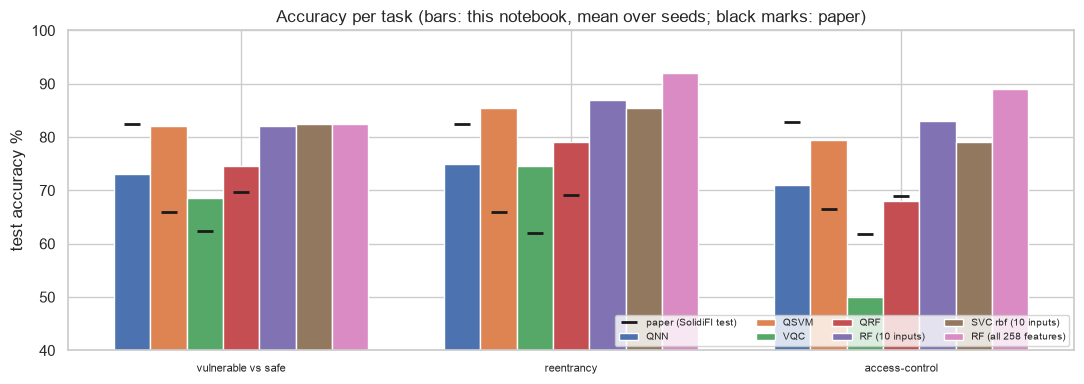

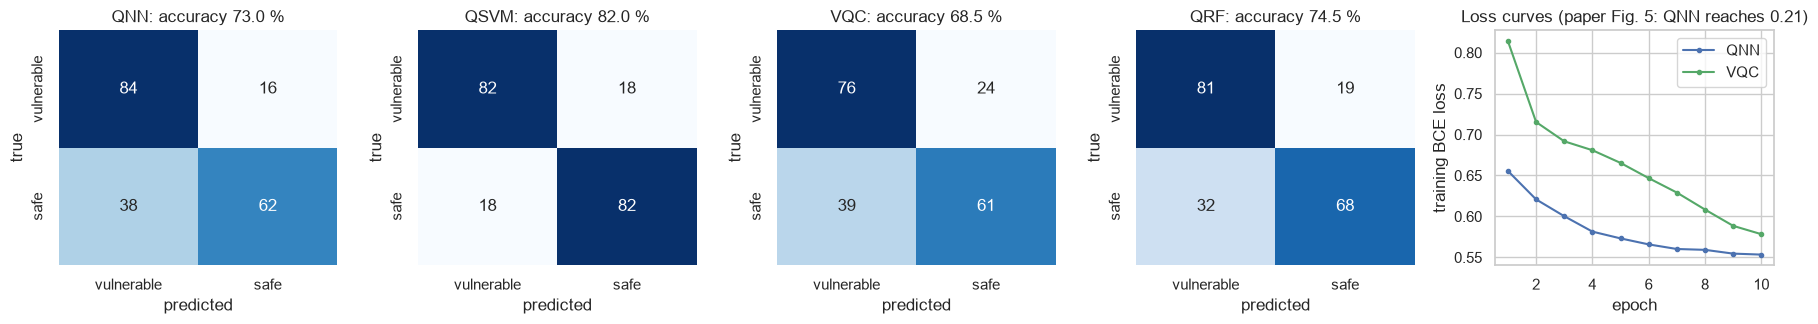

In [17]:
# Figure: accuracy per task and model; the paper's Table 8 / 9 QNN, QSVM, VQC, QRF accuracies are drawn as black markers
PAPER_ACC = {  # Table 8 (all types, SolidiFI) and Table 9 (per type); order QNN, QSVM, VQC, QRF
    "vulnerable vs safe": [82.43, 65.98, 62.41, 69.63],
    "gas-limit (DoS proxy)": [81.55, 65.50, 61.12, 68.15], "uninitialized-storage": [82.10, 64.00, 61.90, 68.90],
    "access-control": [82.80, 66.50, 61.90, 68.90], "reentrancy": [82.43, 66.00, 62.10, 69.20], "arithmetic (overflow proxy)": [82.25, 67.90, 62.41, 69.63]}
fig, ax = plt.subplots(figsize=(11, 4)); w = 0.11
for j, m in enumerate(MODELS):
    vals = [R[(R.task == t) & (R.model == m)].acc.mean() for t in RUN_TASKS]
    ax.bar(np.arange(len(RUN_TASKS)) + (j - 3) * w, vals, w, label=m)
for i, t in enumerate(RUN_TASKS):
    for j in range(4):
        ax.plot(i + (j - 3) * w, PAPER_ACC[t][j], "k_", markersize=12, mew=2)
ax.plot([], [], "k_", markersize=12, mew=2, label="paper (SolidiFI test)")
ax.set_xticks(range(len(RUN_TASKS))); ax.set_xticklabels(RUN_TASKS, fontsize=8); ax.set_ylim(40, 100); ax.set_ylabel("test accuracy %")
ax.set_title("Accuracy per task (bars: this notebook, mean over seeds; black marks: paper)"); ax.legend(ncol=4, fontsize=7, loc="lower right")
plt.tight_layout(); plt.show()

# Figure: confusion matrices (vulnerable = positive class) of the four quantum models on the main task, and training-loss curves (paper Fig. 5)
T0 = "vulnerable vs safe"
fig, axes = plt.subplots(1, 5, figsize=(18, 3.4))
for ax_, m in zip(axes[:4], ["QNN", "QSVM", "VQC", "QRF"]):
    k = keep[(T0, m)]; cm = confusion_matrix(k["y"], k["pred"], labels=[1, 0])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax_, xticklabels=["vulnerable", "safe"], yticklabels=["vulnerable", "safe"])
    ax_.set_title(f"{m}: accuracy {accuracy_score(k['y'], k['pred'])*100:.1f} %"); ax_.set_xlabel("predicted"); ax_.set_ylabel("true")
for m, c in [("QNN", "C0"), ("VQC", "C2")]:
    axes[4].plot(range(1, EPOCHS + 1), keep[(T0, m)]["hist"], c, marker="o", ms=3, label=m)
axes[4].set_xlabel("epoch"); axes[4].set_ylabel("training BCE loss"); axes[4].set_title("Loss curves (paper Fig. 5: QNN reaches 0.21)"); axes[4].legend()
plt.tight_layout(); plt.show()

## 7. McNemar's test (paper Table 11)

The paper compares the QNN with the other models by McNemar's test on the same test samples. For two classifiers A and B on the same test set let `b` = samples A gets right and B wrong and `c` = the reverse. The statistic is `chi2 = (|b - c| - 1)^2 / (b + c)` (continuity corrected, 1 degree of freedom); we also give the exact two-sided binomial p-value, which is the safer choice for small counts. We run it for the main task and for every vulnerability type that ran (first seed). Table 11 of the paper lists only chi-square values and p = 0 or 1 with discordant counts in the thousands, which is more than a test set of 5 000 fragments can contain for four models; we cannot reproduce those counts.

In [18]:
def mcnemar(y, pa, pb):
    ca, cb = (pa == y), (pb == y); b, c = int((ca & ~cb).sum()), int((~ca & cb).sum())
    chi2 = (abs(b - c) - 1) ** 2 / (b + c) if b + c > 0 else 0.0
    return b, c, chi2, float(stats.chi2.sf(chi2, 1)), (float(stats.binomtest(min(b, c), b + c, 0.5).pvalue) if b + c > 0 else 1.0)
mc_rows = []
for task in RUN_TASKS:
    for other in ["QSVM", "VQC", "QRF"]:
        k1, k2 = keep[(task, "QNN")], keep[(task, other)]
        b, c, chi2, p, pe = mcnemar(k1["y"], k1["pred"], k2["pred"])
        mc_rows.append(dict(task=task, comparison=f"QNN vs {other}", b_QNN_right_only=b, c_other_right_only=c, chi2=round(chi2, 2), p_chi2=p, p_exact=pe, significant_5pct=pe < 0.05))
MC = pd.DataFrame(mc_rows); display(MC.round(4))

,task,comparison,b_QNN_right_only,c_other_right_only,chi2,p_chi2,p_exact,significant_5pct
0,vulnerable vs safe,QNN vs QSVM,5,23,10.32,0.0013,0.0009,True
1,vulnerable vs safe,QNN vs VQC,18,9,2.37,0.1237,0.1221,False
2,vulnerable vs safe,QNN vs QRF,9,12,0.19,0.6625,0.6636,False
3,reentrancy,QNN vs QSVM,4,25,13.79,0.0002,0.0001,True
4,reentrancy,QNN vs VQC,5,4,0.00,1.0000,1.0000,False
5,reentrancy,QNN vs QRF,8,16,2.04,0.1530,0.1516,False
6,access-control,QNN vs QSVM,6,23,8.83,0.0030,0.0023,True
7,access-control,QNN vs VQC,68,26,17.88,0.0000,0.0000,True
8,access-control,QNN vs QRF,18,12,0.83,0.3613,0.3616,False


## 8. Stability over seeds and robustness to depolarising noise

The paper reports a stability analysis over ten random seeds and states that under simulated depolarising noise with `p = 0.05` and `p = 0.01` the QML models "retained over 90 % of noiseless accuracy". The seed spread is in the tables above (standard deviation over `SEEDS_BINARY`). For the noise we use **quantum trajectories** on the QNN trained for the main task: after every single-qubit layer and after every CNOT ring, each qubit suffers, with probability `p`, a random Pauli X, Y or Z error, and `<Z_0>` is averaged over trajectories. This is the same single-qubit depolarising channel a density-matrix simulator applies (checked against the analytic one-qubit value above). `# CHOICE:` the paper does not say after which gates the noise acts, nor how it was simulated.

,p,accuracy,retained
0,0.00,73.3,100.0
1,0.01,73.3,100.0
2,0.05,58.3,79.5


60 test contracts, 8 trajectories each


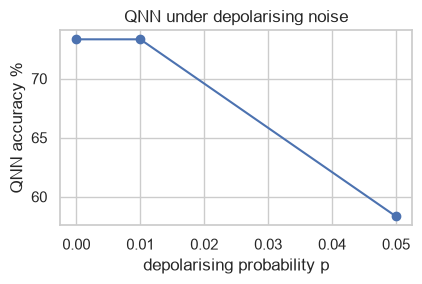

In [19]:
w_q, Ate_q, yte_q = qnn_store[(T0, SEEDS_BINARY[0])]
sel = np.random.default_rng(SEED).choice(len(yte_q), min(N_NOISE_TEST, len(yte_q)), replace=False)
xq = torch.tensor(Ate_q[sel][:, :N_QUBITS], dtype=torch.float64); yq = yte_q[sel]
with torch.no_grad():
    acc0 = float(((qnn_forward(sim10, xq, w_q, ring10) > 0).numpy().astype(int) == yq).mean()) * 100
    noise_rows = [dict(p=0.0, accuracy=acc0, retained=100.0)]
    for p in NOISE_LEVELS:
        gen = torch.Generator().manual_seed(SEED)
        xr = xq.repeat_interleave(N_TRAJ, 0)
        z = qnn_forward(sim10, xr, w_q, ring10, noise=lambda S, p=p: noise_layer(sim10, S, p, gen)).reshape(len(xq), N_TRAJ).mean(1)
        acc = float(((z > 0).numpy().astype(int) == yq).mean()) * 100
        noise_rows.append(dict(p=p, accuracy=acc, retained=acc / acc0 * 100))
NZ = pd.DataFrame(noise_rows); display(NZ.style.format({"p": "{:.2f}", "accuracy": "{:.1f}", "retained": "{:.1f}"}))
print(f"{len(sel)} test contracts, {N_TRAJ} trajectories each")
plt.figure(figsize=(4.5, 3)); plt.plot(NZ.p, NZ.accuracy, "o-"); plt.xlabel("depolarising probability p"); plt.ylabel("QNN accuracy %"); plt.title("QNN under depolarising noise"); plt.tight_layout(); plt.show()

## 9. Side by side with the paper

Verdict rule: a number is **reproduced** if it is within 2 accuracy points (0.02 F1) of the paper, **not reached** if lower by more, **exceeded** if higher by more; **cannot be checked** when the experiment is not possible here (SolidiFI test set, other detectors, Mythril/Slither true-positive counts, proprietary data).

In [20]:
PAPER8 = {"QNN": dict(prec=83.50, acc=82.43, rec=81.17, f1=81.20), "QSVM": dict(prec=68.20, acc=65.98, rec=63.00, f1=64.50),
          "VQC": dict(prec=61.00, acc=62.41, rec=63.30, f1=55.50), "QRF": dict(prec=70.10, acc=69.63, rec=63.50, f1=60.20)}
def verdict(ours, paper, tol=2.0):
    d = ours - paper
    return "reproduced" if abs(d) <= tol else (f"exceeded (+{d:.1f})" if d > 0 else f"not reached ({d:.1f})")
sub = R[R.task == T0]
rows = []
for m in ["QNN", "QSVM", "VQC", "QRF"]:
    for k, lab in [("acc", "accuracy"), ("f1", "F1")]:
        ours = sub[sub.model == m][k].mean()
        rows.append(dict(claim=f"Table 8: {m} {lab} (SolidiFI test)", paper=PAPER8[m][k], notebook=round(ours, 1), verdict=verdict(ours, PAPER8[m][k]) + " [different test set]"))
acc_main = {m: sub[sub.model == m].acc.mean() for m in ["QNN", "QSVM", "VQC", "QRF"]}
rows.append(dict(claim="QNN is the best QML model on the main task", paper="yes (82.43 vs <= 69.63)", notebook=f"best = {max(acc_main, key=acc_main.get)} ({max(acc_main.values()):.1f})",
                 verdict="reproduced" if max(acc_main, key=acc_main.get) == "QNN" else "not reached"))
rows.append(dict(claim="paper's ordering QNN > QRF > QSVM > VQC", paper="yes", notebook=" > ".join(sorted(acc_main, key=acc_main.get, reverse=True)),
                 verdict="reproduced" if sorted(acc_main, key=acc_main.get, reverse=True) == ["QNN", "QRF", "QSVM", "VQC"] else "not reached"))
for t in RUN_TASKS:
    if t == T0: continue
    ours = R[(R.task == t) & (R.model == "QNN")].acc.mean()
    rows.append(dict(claim=f"Table 9: QNN accuracy, {t}", paper=PAPER_ACC[t][0], notebook=round(ours, 1), verdict=verdict(ours, PAPER_ACC[t][0]) + " [Slither proxy label, other test set]"))
for t in TASKS:
    if t not in RUN_TASKS and t != T0:
        rows.append(dict(claim=f"Table 9: QNN accuracy, {t}", paper=PAPER_ACC[t][0], notebook="not run", verdict=(f"cannot be checked (only {len(TASKS[t])} positives in the loaded shards, need {MIN_POS})" if len(TASKS[t]) < MIN_POS else "not run in FAST_MODE (set FAST_MODE = False)")))
rows.append(dict(claim="QNN training loss reaches about 0.21 (Fig. 5)", paper=0.21, notebook=round(keep[(T0, 'QNN')]['hist'][-1], 3),
                 verdict="reproduced" if abs(keep[(T0, 'QNN')]['hist'][-1] - 0.21) < 0.05 else ("exceeded (loss lower)" if keep[(T0, 'QNN')]['hist'][-1] < 0.21 else "not reached (loss higher)")))
sig = MC[MC.task == T0]
rows.append(dict(claim="McNemar: QNN differs significantly from the others (Table 11)", paper="significant for 4 of 5 types",
                 notebook=f"main task: {int(sig.significant_5pct.sum())} of 3 comparisons significant (exact p)", verdict="reproduced" if sig.significant_5pct.all() else "not reached"))
ret = NZ[NZ.p > 0].retained.min()
rows.append(dict(claim="QNN keeps > 90 % of noiseless accuracy at p = 0.01 / 0.05", paper=">90 %", notebook=f"min retained {ret:.1f} %", verdict="reproduced" if ret > 90 else "not reached"))
rows.append(dict(claim="Table 10 / Fig. 3: QNN finds more true positives than Mythril, Smartcheck, Slither", paper="QNN 65/89/225/351 vs Slither 35/66/198/300", notebook="detectors not run on SolidiFI", verdict="cannot be checked"))
rows.append(dict(claim="Hardware-level robustness, SolidiFI generalisation, 97.63 % on test set (introduction)", paper="various", notebook="-", verdict="cannot be checked"))
CMP = pd.DataFrame(rows); pd.set_option("display.max_colwidth", 80, "display.width", 250); display(CMP)
print("paper ordering of the means (this notebook):", {m: round(v, 1) for m, v in acc_main.items()})
print("classical baselines on the same inputs:", {m: round(sub[sub.model == m].acc.mean(), 1) for m in ["RF (10 inputs)", "SVC rbf (10 inputs)", "RF (all 258 features)"]})
print(f"total notebook time {(time.time()-T_NOTEBOOK)/60:.1f} min")

,claim,paper,notebook,verdict
0,Table 8: QNN accuracy (SolidiFI test),82.43,73.0,not reached (-9.4) [different test set]
1,Table 8: QNN F1 (SolidiFI test),81.2,75.7,not reached (-5.5) [different test set]
2,Table 8: QSVM accuracy (SolidiFI test),65.98,82.0,exceeded (+16.0) [different test set]
3,Table 8: QSVM F1 (SolidiFI test),64.5,82.0,exceeded (+17.5) [different test set]
4,Table 8: VQC accuracy (SolidiFI test),62.41,68.5,exceeded (+6.1) [different test set]
5,Table 8: VQC F1 (SolidiFI test),55.5,70.7,exceeded (+15.2) [different test set]
6,Table 8: QRF accuracy (SolidiFI test),69.63,74.5,exceeded (+4.9) [different test set]
7,Table 8: QRF F1 (SolidiFI test),60.2,76.1,exceeded (+15.9) [different test set]
8,QNN is the best QML model on the main task,yes (82.43 vs <= 69.63),best = QSVM (82.0),not reached
9,paper's ordering QNN > QRF > QSVM > VQC,yes,QSVM > QRF > QNN > VQC,not reached


paper ordering of the means (this notebook): {'QNN': np.float64(73.0), 'QSVM': np.float64(82.0), 'VQC': np.float64(68.5), 'QRF': np.float64(74.5)}
classical baselines on the same inputs: {'RF (10 inputs)': np.float64(82.0), 'SVC rbf (10 inputs)': np.float64(82.5), 'RF (all 258 features)': np.float64(82.5)}
total notebook time 11.6 min


## 10. Reading the paper critically

- **The test set is not in distribution with the training set, but also not described well enough to rebuild.** SolidiFI injects bugs into otherwise clean contracts; the same contract appears with and without the bug. The paper does not say how the 5 000 SolidiFI "code fragments" were labelled per type or compiled (SolidiFI sources use several Solidity versions), and the expert-audited set is not public ("on reasonable request"). Here we test on a held-out part of the Slither set instead, so the numbers are not comparable one-to-one.
- **Labels are tool outputs.** Our positives are what Slither flags, so a model that learns "looks like Slither's flagged contracts" can reach high scores without finding real bugs; the paper's training labels are partly Slither labels as well. Detectors such as `divide-before-multiply` or `msg-value-loop` are only proxies for "overflow" and "gas limit".
- **Duplicates.** Token contracts are copied thousands of times on Ethereum. We removed identical bytecode and identical feature vectors; without it, test accuracy of every model (also the classical ones) rises sharply because near-copies sit in both splits. The paper says duplicates were removed but does not say how.
- **The circuit description is thin.** Section 3.5 describes a Ventura-style loader for a *set* of binary patterns; Section 3.7 uses ordinary angle encoding. Table 4 lists dropout and fully connected layers that a pure circuit does not have, with a learning rate of 1e-5 and up to 500 epochs, while the text mentions "2000 epochs". Without a code release the architecture, the qubit number of the QNN and the read-out cannot be pinned down; ours is one consistent reading.
- **Why can a QNN beat a QSVM by 17 points in the paper?** The three other models score 62-70 %, close to the 50 % chance level of a balanced test, while the QNN scores 82 %. A fair comparison needs tuned classical baselines on the same inputs (Random Forest and SVM above), several seeds, and the same optimisation budget. The paper reports none of these, and Table 9 repeats the same numbers across vulnerability types with differences of a few tenths, which is unusual for independent experiments.
- **McNemar's test with thousands of discordant pairs** (Table 11) on a test set of 5 000 fragments is not possible for four models and five types; the table also lists `p = 0` and `p = 1` which look like rounded or placeholder values.
- **"Less storage and memory" is not shown.** The contribution list claims QML needs less memory; all experiments use classical state-vector simulators, whose memory grows as 2^n.

## Exercises

1. Change `N_QUBITS` to 6 or 8 and compare QNN, VQC and the Random Forest on the same PCA inputs. Does the quantum model benefit from more qubits, or the classical one from more features? Use `RF (all 258 features)` as the upper reference.
2. Replace the exact-duplicate removal by none at all (comment out the two `drop_duplicates` calls) and re-run. By how many points does every model gain, and what does that say about the paper's claim?
3. Replace the QNN's CNOT ring by no entangling gates at all (use `perm = identity`). Does the accuracy fall? This tests whether the "entangling operations" the paper credits for the QNN's advantage matter on this data.
4. Compile the SolidiFI contracts yourself (`py-solc-x`, the right `solc` per file), build the same 258 features from their runtime bytecode, and test the trained models on them. How large is the drop from the in-distribution test set?
5. Add the `time-manipulation` and `unchecked-calls` classes from `label_mappings.json` as further tasks, and use the McNemar function of Section 7 to test the QNN against the Random Forest instead of against the other quantum models.

### Budgets of the full run (`FAST_MODE = False`)

All 9 shards (about 135 000 contracts, all the rare `uninitialized-storage` and loop detectors are kept), 3 000 ordinary contracts per shard, 800 contracts per class and task with a 70/30 split, 25 epochs for QNN and VQC, 4 bandwidths for the QSVM, 220 quantum decision trees of 25 Adam steps each, ten seeds for the main task and one seed per vulnerability type (up to five types), 200 noise-test contracts with 16 trajectories. On a CPU shared with other jobs this takes several hours; on a free Colab CPU expect a similar order of magnitude.